# 1. 	Import dan pemeriksaan dataset

In [ ]:
!pip -q install scikit-learn==1.8.0

In [ ]:
# Pengolahan data
import pandas as pd
import numpy as np
import os
import time
import json

# Machine Learning
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

# Model klasifikasi
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

# Evaluasi
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Cross Validation
from sklearn.model_selection import StratifiedGroupKFold

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Penyimpanan model
import joblib

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

print("Library berhasil diimpor.")
print("Scikit-learn version:", sklearn.__version__)

Library berhasil diimpor.
Scikit-learn version: 1.8.0


In [ ]:
import torch

print("CUDA tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU tidak terdeteksi.")

CUDA tersedia: True
GPU: Tesla T4


In [ ]:
# Membuat folder output
folders = [
    "outputs",
    "outputs/predictions",
    "outputs/tables",
    "outputs/figures",
    "outputs/models"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Struktur folder berhasil dibuat.")

Struktur folder berhasil dibuat.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving data_eksperimen.csv to data_eksperimen.csv


In [ ]:
# Lokasi dataset
PATH_DATA = "data_eksperimen.csv"

# Membaca dataset
df = pd.read_csv(
    PATH_DATA,
    keep_default_na=False,
    dtype={
        "mdr_report_key": str,
        "date_received": str
    }
)

# Memastikan tipe data fold sesuai
df["fold"] = df["fold"].astype(int)

print("Dataset berhasil dimuat.")
print("Dimensi dataset:", df.shape)

display(df.head())

Dataset berhasil dimuat.
Dimensi dataset: (3604, 11)


,mdr_report_key,date_received,tahun,manufacturer,label,grup,fold,event_text,norm,text_clean,text_tf
0,221,19920128,1992,GENERAL ELECTRIC,Injury,0,4,OUTPATIENT UNDER GENERAL ANESTHESIA FOR LUMBAR SCAN INMRI. PATIENT RECEIVED BURNS UNDER 3 ECG ELECTRODES. BURNS NO...,outpatient under general anesthesia for lumbar scan inmri patient received burns under ecg electrodes burns noticed ...,outpatient under general anesthesia for lumbar scan inmri patient received burns under ecg electrodes burns noticed ...,outpatient under general anesthesia for lumbar scan inmri. patient received burns under 3 ecg electrodes. burns noti...
1,1664,19921102,1992,GENERAL ELECTRIC,Injury,1,4,"PATIENT WAS BEING SCANNED IN THE THORACIC SPINE AREA USING THE QUAD T&L COIL. PATIENT ORIENTATION WAS HEAD FIRST, S...",patient was being scanned in the thoracic spine area using the quad t l coil patient orientation was head first supl...,patient was being scanned in the thoracic spine area using the quad t l coil patient orientation was head first supl...,"patient was being scanned in the thoracic spine area using the quad t&l coil. patient orientation was head first, su..."
2,3890,19930219,1993,"PHILIPS MEDICAL SYSTEMS, INC.",Injury,2,3,PATIENT WAS UNDERGOING MRI SCANNING OF LT. KNEE FOR PAIN. PATIENT HAD RT. KNEE REPLACEMENT DONE ON 7/14/92. DURING...,patient was undergoing mri scanning of lt knee for pain patient had rt knee replacement done on during scan patient ...,patient was undergoing mri scanning of lt knee for pain patient had rt knee replacement done on during scan patient ...,patient was undergoing mri scanning of lt. knee for pain. patient had rt. knee replacement done on 7/14/92. during s...
3,10418,19931208,1993,TOSHIBA AMERICA MEDICAL SYSTEMS,Other,3,2,PT HAD A L-SPINE MRI SCAN. AS PT WAS BEING REMOVED FROM SCANNER HE COMPLAINTED OF A BURNING SENSATION ON HIS THUMB A...,pt had a l spine mri scan as pt was being removed from scanner he complainted of a burning sensation on his thumb an...,pt had a l spine mri scan as pt was being removed from scanner he complainted of a burning sensation on his thumb an...,pt had a l-spine mri scan. as pt was being removed from scanner he complainted of a burning sensation on his thumb a...
4,12691,19940412,1994,PICKER INTL,Injury,4,2,TESTS HAVE SHOWN TWO MRI SESSIONS TRIGGERED ELECTRO-MAGNETIC FIELD HYPERSENSITIVITY (EMFH). RPTR FELT TINGLING DURIN...,tests have shown two mri sessions triggered electro magnetic field hypersensitivity emfh rptr felt tingling during m...,tests have shown two mri sessions triggered electro magnetic field hypersensitivity emfh rptr felt tingling during m...,tests have shown two mri sessions triggered electro-magnetic field hypersensitivity (emfh). rptr felt tingling durin...


In [ ]:
print("Daftar kolom:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()

# Kolom wajib
required_columns = [
    "mdr_report_key",
    "date_received",
    "tahun",
    "manufacturer",
    "label",
    "grup",
    "fold",
    "event_text",
    "norm",
    "text_clean",
    "text_tf"
]

# Memeriksa kolom
missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

assert len(missing_columns) == 0, (
    f"Kolom tidak ditemukan: {missing_columns}"
)

# Urutan kelas yang digunakan
CLASS_ORDER = [
    "Death",
    "Injury",
    "Malfunction",
    "Other"
]

# Memeriksa jumlah data
assert len(df) == 3604

# Memeriksa ID laporan
assert df["mdr_report_key"].is_unique

# Memeriksa label
assert df["label"].isin(CLASS_ORDER).all()

# Memeriksa fold
assert set(df["fold"].unique()) == {0, 1, 2, 3, 4}

# Memeriksa teks
assert (df["text_clean"].str.strip() != "").all()
assert (df["text_tf"].str.strip() != "").all()

# Memeriksa konsistensi grup dan fold
assert df.groupby("grup")["fold"].nunique().max() == 1

print("Seluruh pemeriksaan dataset berhasil dilewati.")

# Distribusi label
print("Distribusi kelas:")
display(
    df["label"]
    .value_counts()
    .reindex(CLASS_ORDER)
    .to_frame("Jumlah")
)

# Distribusi label pada setiap fold
print("\nDistribusi kelas setiap fold:")
display(
    pd.crosstab(df["fold"], df["label"])
    .reindex(columns=CLASS_ORDER)
)

Daftar kolom:
['mdr_report_key', 'date_received', 'tahun', 'manufacturer', 'label', 'grup', 'fold', 'event_text', 'norm', 'text_clean', 'text_tf']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3604 entries, 0 to 3603
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   mdr_report_key  3604 non-null   object
 1   date_received   3604 non-null   object
 2   tahun           3604 non-null   int64 
 3   manufacturer    3604 non-null   object
 4   label           3604 non-null   object
 5   grup            3604 non-null   int64 
 6   fold            3604 non-null   int64 
 7   event_text      3604 non-null   object
 8   norm            3604 non-null   object
 9   text_clean      3604 non-null   object
 10  text_tf         3604 non-null   object
dtypes: int64(3), object(8)
memory usage: 309.8+ KB
Seluruh pemeriksaan dataset berhasil dilewati.
Distribusi kelas:


,Jumlah
label,
Death,36
Injury,2144
Malfunction,1082
Other,342



Distribusi kelas setiap fold:


label,Death,Injury,Malfunction,Other
fold,,,,
0,7,429,217,68
1,7,429,216,69
2,8,429,216,68
3,7,428,217,69
4,7,429,216,68


In [ ]:
# Fitur teks untuk model klasik
X = df["text_clean"]

# Target klasifikasi
y = df["label"]

# Identitas grup untuk cross-validation
groups = df["grup"]

# Fold yang sudah ditentukan pada Tahap 2
folds = df["fold"]

# Identitas laporan
report_ids = df["mdr_report_key"]

print("Jumlah data:", len(X))
print("Jumlah kelas:", y.nunique())
print("Jumlah grup:", groups.nunique())
print("Jumlah fold:", folds.nunique())

Jumlah data: 3604
Jumlah kelas: 4
Jumlah grup: 3503
Jumlah fold: 5


# 2. Out-of-Fold (OOF) Prediction

In [ ]:
from sklearn.base import clone
from sklearn.metrics import f1_score

print("Persiapan fungsi OOF berhasil.")

Persiapan fungsi OOF berhasil.


In [ ]:
def run_oof(model, X, y, folds, groups, report_ids, model_name):

    # Menyiapkan tempat penyimpanan prediksi
    oof_predictions = pd.DataFrame({
        "mdr_report_key": report_ids.values,
        "fold": folds.values,
        "y_true": y.values,
        "y_pred": None
    })

    # Menyimpan waktu pelatihan setiap fold
    fold_times = []

    # Memastikan setiap fold digunakan sebagai data uji
    unique_folds = sorted(folds.unique())

    for fold in unique_folds:

        print(f"\nMenjalankan Fold {fold}...")

        # Membagi data latih dan data uji
        train_idx = folds != fold
        test_idx = folds == fold

        X_train = X[train_idx]
        X_test = X[test_idx]

        y_train = y[train_idx]
        y_test = y[test_idx]

        # Memastikan tidak ada grup yang bocor
        train_groups = set(groups[train_idx])
        test_groups = set(groups[test_idx])

        assert train_groups.isdisjoint(test_groups), (
            f"Data leakage ditemukan pada Fold {fold}"
        )

        # Membuat model baru
        fold_model = clone(model)

        # Melatih model dan mengukur waktu
        start_time = time.time()

        fold_model.fit(X_train, y_train)

        elapsed_time = time.time() - start_time
        fold_times.append(elapsed_time)

        # Melakukan prediksi pada data uji
        y_pred = fold_model.predict(X_test)

        # Menyimpan hasil prediksi sesuai posisi data
        oof_predictions.loc[test_idx, "y_pred"] = y_pred

        print(
            f"Fold {fold} selesai | "
            f"Data latih: {len(X_train)} | "
            f"Data uji: {len(X_test)} | "
            f"Waktu: {elapsed_time:.2f} detik"
        )

    # Memastikan seluruh laporan sudah memperoleh prediksi
    assert oof_predictions["y_pred"].notna().all()

    # Menghitung Macro-F1 keseluruhan
    macro_f1 = f1_score(
        oof_predictions["y_true"],
        oof_predictions["y_pred"],
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    # Ringkasan hasil
    summary = {
        "model": model_name,
        "macro_f1": macro_f1,
        "mean_training_time": np.mean(fold_times),
        "total_training_time": np.sum(fold_times)
    }

    print("\nOOF selesai.")
    print(f"Model       : {model_name}")
    print(f"Macro-F1    : {macro_f1:.4f}")
    print(f"Rata-rata waktu pelatihan: {np.mean(fold_times):.2f} detik")

    return oof_predictions, summary

In [ ]:
# Pipeline TF-IDF dan Complement Naive Bayes
test_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.9,
            sublinear_tf=True,
            stop_words="english"
        )
    ),
    (
        "classifier",
        ComplementNB(alpha=0.3)
    )
])

print("Pipeline model percobaan berhasil dibuat.")

Pipeline model percobaan berhasil dibuat.


In [ ]:
oof_test, summary_test = run_oof(
    model=test_model,
    X=X,
    y=y,
    folds=folds,
    groups=groups,
    report_ids=report_ids,
    model_name="ComplementNB_Word_TFIDF_Test"
)


Menjalankan Fold 0...
Fold 0 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 0.38 detik

Menjalankan Fold 1...
Fold 1 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 0.35 detik

Menjalankan Fold 2...
Fold 2 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 0.32 detik

Menjalankan Fold 3...
Fold 3 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 0.32 detik

Menjalankan Fold 4...
Fold 4 selesai | Data latih: 2884 | Data uji: 720 | Waktu: 0.33 detik

OOF selesai.
Model       : ComplementNB_Word_TFIDF_Test
Macro-F1    : 0.6023
Rata-rata waktu pelatihan: 0.34 detik


In [ ]:
print("Dimensi hasil prediksi:", oof_test.shape)

print("\nLima baris pertama:")
display(oof_test.head())

print("\nDistribusi label sebenarnya:")
display(oof_test["y_true"].value_counts())

print("\nDistribusi hasil prediksi:")
display(oof_test["y_pred"].value_counts())

print("\nJumlah prediksi kosong:", oof_test["y_pred"].isna().sum())
print("Jumlah ID unik:", oof_test["mdr_report_key"].nunique())

Dimensi hasil prediksi: (3604, 4)

Lima baris pertama:


,mdr_report_key,fold,y_true,y_pred
0,221,4,Injury,Injury
1,1664,4,Injury,Injury
2,3890,3,Injury,Injury
3,10418,2,Other,Injury
4,12691,2,Injury,Injury



Distribusi label sebenarnya:


,count
y_true,
Injury,2144
Malfunction,1082
Other,342
Death,36



Distribusi hasil prediksi:


,count
y_pred,
Injury,2567
Malfunction,878
Other,150
Death,9



Jumlah prediksi kosong: 0
Jumlah ID unik: 3604


In [ ]:
oof_test.to_csv(
    "outputs/predictions/complement_nb_test.csv",
    index=False
)

print("Hasil prediksi percobaan berhasil disimpan.")

Hasil prediksi percobaan berhasil disimpan.


# 3. Modeling Word TF-IDF

In [ ]:
## Fungsi Word TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

def make_word_tfidf():
    return TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.9,
        sublinear_tf=True,
        stop_words="english"
    )


In [ ]:

from sklearn.pipeline import Pipeline

from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier


In [ ]:
## Complement Naive Bayes
model_cnb = Pipeline([
    ("tfidf", make_word_tfidf()),
    ("classifier", ComplementNB(alpha=0.3))
])


In [ ]:
## Logistic Regression
model_lr = Pipeline([
    ("tfidf", make_word_tfidf()),
    ("classifier", LogisticRegression(
        C=10,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])


In [ ]:
## LinearSVC
model_svm = Pipeline([
    ("tfidf", make_word_tfidf()),
    ("classifier", LinearSVC(
        C=0.5,
        class_weight="balanced",
        random_state=42
    ))
])


In [ ]:
## Random Forest
model_rf = Pipeline([
    ("tfidf", make_word_tfidf()),
    ("classifier", RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])


In [ ]:

word_models = {
    "ComplementNB_Word": model_cnb,
    "LogisticRegression_Word": model_lr,
    "LinearSVC_Word": model_svm,
    "RandomForest_Word": model_rf
}

word_results = []


In [ ]:

for model_name, model in word_models.items():

    print("\n" + "="*60)
    print(f"MODEL: {model_name}")
    print("="*60)

    predictions, summary = run_oof(
        model=model,
        X=X,
        y=y,
        folds=folds,
        groups=groups,
        report_ids=report_ids,
        model_name=model_name
    )

    predictions["y_pred"] = predictions["y_pred"].astype(str)

    output_path = f"outputs/predictions/{model_name.lower()}.csv"
    predictions.to_csv(output_path, index=False)

    word_results.append(summary)

    print(f"\nPredictions saved: {output_path}")
    print(f"Macro-F1: {summary['macro_f1']:.4f}")
    print(f"Average training time: {summary['mean_training_time']:.2f} seconds")


MODEL: ComplementNB_Word

Menjalankan Fold 0...
Fold 0 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 0.31 detik

Menjalankan Fold 1...
Fold 1 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 0.33 detik

Menjalankan Fold 2...
Fold 2 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 0.32 detik

Menjalankan Fold 3...
Fold 3 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 0.33 detik

Menjalankan Fold 4...
Fold 4 selesai | Data latih: 2884 | Data uji: 720 | Waktu: 0.32 detik

OOF selesai.
Model       : ComplementNB_Word
Macro-F1    : 0.6023
Rata-rata waktu pelatihan: 0.32 detik

Predictions saved: outputs/predictions/complementnb_word.csv
Macro-F1: 0.6023
Average training time: 0.32 seconds

MODEL: LogisticRegression_Word

Menjalankan Fold 0...
Fold 0 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 1.89 detik

Menjalankan Fold 1...
Fold 1 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 2.92 detik

Menjalankan Fold 2...
Fold 2 selesai | Data latih: 2883 | Data uji: 72

In [ ]:

word_results_df = pd.DataFrame(word_results)

word_results_df = word_results_df.sort_values(
    by="macro_f1",
    ascending=False
).reset_index(drop=True)

display(word_results_df)


,model,macro_f1,mean_training_time,total_training_time
0,LogisticRegression_Word,0.672610,2.521705,12.608524
1,LinearSVC_Word,0.660492,0.800116,4.000578
2,ComplementNB_Word,0.602263,0.329214,1.646069
3,ComplementNB_Word,0.602263,0.323488,1.617440
4,RandomForest_Word,0.515702,15.421466,77.107331


In [ ]:
word_results_df.to_csv(
    "outputs/tables/word_tfidf_model_comparison.csv",
    index=False
)

print("Tabel perbandingan Word TF-IDF berhasil disimpan.")

Tabel perbandingan Word TF-IDF berhasil disimpan.


In [ ]:
from sklearn.metrics import classification_report

for model_name in word_models.keys():

    file_path = f"outputs/predictions/{model_name.lower()}.csv"
    pred_df = pd.read_csv(file_path)

    print("\n" + "="*60)
    print(f"CLASSIFICATION REPORT: {model_name}")
    print("="*60)

    print(classification_report(
        pred_df["y_true"],
        pred_df["y_pred"],
        labels=CLASS_ORDER,
        target_names=CLASS_ORDER,
        zero_division=0,
        digits=4
    ))



CLASSIFICATION REPORT: ComplementNB_Word
              precision    recall  f1-score   support

       Death     0.6667    0.1667    0.2667        36
      Injury     0.8111    0.9711    0.8839      2144
 Malfunction     0.9374    0.7606    0.8398      1082
       Other     0.6867    0.3012    0.4187       342

    accuracy                         0.8363      3604
   macro avg     0.7754    0.5499    0.6023      3604
weighted avg     0.8357    0.8363    0.8203      3604


CLASSIFICATION REPORT: LogisticRegression_Word
              precision    recall  f1-score   support

       Death     0.7692    0.2778    0.4082        36
      Injury     0.8622    0.9193    0.8898      2144
 Malfunction     0.9002    0.8253    0.8611      1082
       Other     0.5559    0.5088    0.5313       342

    accuracy                         0.8457      3604
   macro avg     0.7719    0.6328    0.6726      3604
weighted avg     0.8436    0.8457    0.8424      3604


CLASSIFICATION REPORT: LinearSVC_Word
 

In [ ]:

for model_name in word_models.keys():

    file_path = f"outputs/predictions/{model_name.lower()}.csv"
    pred_df = pd.read_csv(file_path)

    print(f"\n{model_name}")
    print("-"*40)
    print("Jumlah prediksi :", len(pred_df))
    print("Jumlah ID unik  :", pred_df["mdr_report_key"].nunique())
    print("Prediksi kosong :", pred_df["y_pred"].isna().sum())
    print("Duplikasi ID    :", pred_df["mdr_report_key"].duplicated().sum())


ComplementNB_Word
----------------------------------------
Jumlah prediksi : 3604
Jumlah ID unik  : 3604
Prediksi kosong : 0
Duplikasi ID    : 0

LogisticRegression_Word
----------------------------------------
Jumlah prediksi : 3604
Jumlah ID unik  : 3604
Prediksi kosong : 0
Duplikasi ID    : 0

LinearSVC_Word
----------------------------------------
Jumlah prediksi : 3604
Jumlah ID unik  : 3604
Prediksi kosong : 0
Duplikasi ID    : 0

RandomForest_Word
----------------------------------------
Jumlah prediksi : 3604
Jumlah ID unik  : 3604
Prediksi kosong : 0
Duplikasi ID    : 0


# 4. Modeling Character TF-IDF

In [ ]:
## Fungsi Character TF-IDF
def make_char_tfidf():
    return TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        min_df=2,
        max_features=200000,
        sublinear_tf=True
    )


In [ ]:
## Model Character TF-IDF + LinearSVC
model_char_svm = Pipeline([
    ("tfidf", make_char_tfidf()),
    ("classifier", LinearSVC(
        C=0.5,
        class_weight="balanced",
        random_state=42
    ))
])


In [ ]:

char_predictions, char_summary = run_oof(
    model=model_char_svm,
    X=X,
    y=y,
    folds=folds,
    groups=groups,
    report_ids=report_ids,
    model_name="LinearSVC_Char"
)

char_predictions["y_pred"] = char_predictions["y_pred"].astype(str)



Menjalankan Fold 0...
Fold 0 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 2.65 detik

Menjalankan Fold 1...
Fold 1 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 1.93 detik

Menjalankan Fold 2...
Fold 2 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 1.89 detik

Menjalankan Fold 3...
Fold 3 selesai | Data latih: 2883 | Data uji: 721 | Waktu: 2.86 detik

Menjalankan Fold 4...
Fold 4 selesai | Data latih: 2884 | Data uji: 720 | Waktu: 2.00 detik

OOF selesai.
Model       : LinearSVC_Char
Macro-F1    : 0.6715
Rata-rata waktu pelatihan: 2.27 detik


In [ ]:

char_predictions.to_csv(
    "outputs/predictions/linearsvc_char.csv",
    index=False
)

print("Prediksi Character TF-IDF berhasil disimpan.")


Prediksi Character TF-IDF berhasil disimpan.


In [ ]:

print("Macro-F1:", round(char_summary["macro_f1"], 4))
print(
    "Average training time:",
    round(char_summary["mean_training_time"], 2),
    "seconds"
)

print("\nClassification Report:")

print(classification_report(
    char_predictions["y_true"],
    char_predictions["y_pred"],
    labels=CLASS_ORDER,
    target_names=CLASS_ORDER,
    zero_division=0,
    digits=4
))

Macro-F1: 0.6715
Average training time: 2.27 seconds

Classification Report:
              precision    recall  f1-score   support

       Death     0.6875    0.3056    0.4231        36
      Injury     0.8636    0.9128    0.8875      2144
 Malfunction     0.8821    0.8299    0.8552      1082
       Other     0.5526    0.4912    0.5201       342

    accuracy                         0.8418      3604
   macro avg     0.7465    0.6349    0.6715      3604
weighted avg     0.8379    0.8418    0.8383      3604



In [ ]:

print("Jumlah prediksi:", len(char_predictions))
print(
    "Jumlah ID unik:",
    char_predictions["mdr_report_key"].nunique()
)
print(
    "Prediksi kosong:",
    char_predictions["y_pred"].isna().sum()
)
print(
    "Duplikasi ID:",
    char_predictions["mdr_report_key"].duplicated().sum()
)

assert len(char_predictions) == 3604
assert char_predictions["mdr_report_key"].nunique() == 3604
assert char_predictions["y_pred"].notna().all()


Jumlah prediksi: 3604
Jumlah ID unik: 3604
Prediksi kosong: 0
Duplikasi ID: 0


# 5. Hyperparameter tuning

In [ ]:
from sklearn.model_selection import GridSearchCV
import gc

In [ ]:
## Fungsi GridSearchCV dalam outer fold
def run_nested_oof(
    pipeline,
    param_grid,
    X,
    y,
    folds,
    groups,
    report_ids,
    model_name,
    inner_splits=3
):
    predictions = pd.DataFrame({
        "mdr_report_key": report_ids.values,
        "fold": folds.values,
        "y_true": y.values,
        "y_pred": None
    })

    tuning_records = []
    fold_times = []

    for outer_fold in sorted(folds.unique()):

        print("\n" + "="*60)
        print(f"{model_name} | OUTER FOLD {outer_fold}")
        print("="*60)

        train_mask = folds != outer_fold
        test_mask = folds == outer_fold

        X_train = X.loc[train_mask]
        X_test = X.loc[test_mask]

        y_train = y.loc[train_mask]
        y_test = y.loc[test_mask]

        groups_train = groups.loc[train_mask]
        groups_test = groups.loc[test_mask]

        assert set(groups_train).isdisjoint(set(groups_test))

        inner_cv = StratifiedGroupKFold(
            n_splits=inner_splits,
            shuffle=True,
            random_state=42
        )

        search = GridSearchCV(
            estimator=clone(pipeline),
            param_grid=param_grid,
            scoring="f1_macro",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            verbose=0
        )

        start_time = time.time()

        search.fit(
            X_train,
            y_train,
            groups=groups_train
        )

        elapsed = time.time() - start_time
        fold_times.append(elapsed)

        best_model = search.best_estimator_
        y_pred = best_model.predict(X_test)

        predictions.loc[test_mask, "y_pred"] = y_pred

        tuning_records.append({
            "model": model_name,
            "outer_fold": outer_fold,
            "best_params": search.best_params_,
            "best_inner_macro_f1": search.best_score_,
            "outer_macro_f1": f1_score(
                y_test,
                y_pred,
                labels=CLASS_ORDER,
                average="macro",
                zero_division=0
            ),
            "training_time": elapsed
        })

        print("Best parameters:", search.best_params_)
        print("Best inner Macro-F1:", round(search.best_score_, 4))
        print(
            "Outer Macro-F1:",
            round(tuning_records[-1]["outer_macro_f1"], 4)
        )

        del search, best_model
        gc.collect()

    predictions["y_pred"] = predictions["y_pred"].astype(str)

    assert predictions["y_pred"].notna().all()

    overall_macro_f1 = f1_score(
        predictions["y_true"],
        predictions["y_pred"],
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    summary = {
        "model": model_name,
        "macro_f1": overall_macro_f1,
        "mean_train_time": np.mean(fold_times),
        "std_train_time": np.std(fold_times)
    }

    return (
        predictions,
        pd.DataFrame(tuning_records),
        summary
    )


In [ ]:
## Tuning ComplementNB
cnb_tuned_pred, cnb_tuning, cnb_tuned_summary = run_nested_oof(
    pipeline=Pipeline([
        ("tfidf", make_word_tfidf()),
        ("classifier", ComplementNB())
    ]),
    param_grid={
        "classifier__alpha": [0.1, 0.3, 1]
    },
    X=X,
    y=y,
    folds=folds,
    groups=groups,
    report_ids=report_ids,
    model_name="ComplementNB_Word_Tuned"
)


ComplementNB_Word_Tuned | OUTER FOLD 0
Best parameters: {'classifier__alpha': 0.1}
Best inner Macro-F1: 0.575
Outer Macro-F1: 0.6587

ComplementNB_Word_Tuned | OUTER FOLD 1
Best parameters: {'classifier__alpha': 0.1}
Best inner Macro-F1: 0.6291
Outer Macro-F1: 0.5704

ComplementNB_Word_Tuned | OUTER FOLD 2
Best parameters: {'classifier__alpha': 0.1}
Best inner Macro-F1: 0.6366
Outer Macro-F1: 0.5867

ComplementNB_Word_Tuned | OUTER FOLD 3
Best parameters: {'classifier__alpha': 0.1}
Best inner Macro-F1: 0.5951
Outer Macro-F1: 0.6663

ComplementNB_Word_Tuned | OUTER FOLD 4
Best parameters: {'classifier__alpha': 0.1}
Best inner Macro-F1: 0.6043
Outer Macro-F1: 0.5484


In [ ]:
## Tuning Logistic Regression
lr_tuned_pred, lr_tuning, lr_tuned_summary = run_nested_oof(
    pipeline=Pipeline([
        ("tfidf", make_word_tfidf()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),
    param_grid={
        "classifier__C": [0.1, 0.5, 1, 10]
    },
    X=X,
    y=y,
    folds=folds,
    groups=groups,
    report_ids=report_ids,
    model_name="LogisticRegression_Word_Tuned"
)



LogisticRegression_Word_Tuned | OUTER FOLD 0
Best parameters: {'classifier__C': 10}
Best inner Macro-F1: 0.6018
Outer Macro-F1: 0.7431

LogisticRegression_Word_Tuned | OUTER FOLD 1
Best parameters: {'classifier__C': 10}
Best inner Macro-F1: 0.712
Outer Macro-F1: 0.5874

LogisticRegression_Word_Tuned | OUTER FOLD 2
Best parameters: {'classifier__C': 10}
Best inner Macro-F1: 0.6767
Outer Macro-F1: 0.6476

LogisticRegression_Word_Tuned | OUTER FOLD 3
Best parameters: {'classifier__C': 1}
Best inner Macro-F1: 0.662
Outer Macro-F1: 0.656

LogisticRegression_Word_Tuned | OUTER FOLD 4
Best parameters: {'classifier__C': 1}
Best inner Macro-F1: 0.6611
Outer Macro-F1: 0.6744


In [ ]:
## Tuning LinearSVC Word TF-IDF
svm_tuned_pred, svm_tuning, svm_tuned_summary = run_nested_oof(
    pipeline=Pipeline([
        ("tfidf", make_word_tfidf()),
        ("classifier", LinearSVC(
            class_weight="balanced",
            random_state=42
        ))
    ]),
    param_grid={
        "classifier__C": [0.1, 0.5, 1, 10]
    },
    X=X,
    y=y,
    folds=folds,
    groups=groups,
    report_ids=report_ids,
    model_name="LinearSVC_Word_Tuned"
)



LinearSVC_Word_Tuned | OUTER FOLD 0
Best parameters: {'classifier__C': 0.5}
Best inner Macro-F1: 0.5986
Outer Macro-F1: 0.6963

LinearSVC_Word_Tuned | OUTER FOLD 1
Best parameters: {'classifier__C': 1}
Best inner Macro-F1: 0.6787
Outer Macro-F1: 0.596

LinearSVC_Word_Tuned | OUTER FOLD 2
Best parameters: {'classifier__C': 1}
Best inner Macro-F1: 0.6613
Outer Macro-F1: 0.6337

LinearSVC_Word_Tuned | OUTER FOLD 3
Best parameters: {'classifier__C': 1}
Best inner Macro-F1: 0.6585
Outer Macro-F1: 0.6895

LinearSVC_Word_Tuned | OUTER FOLD 4
Best parameters: {'classifier__C': 10}
Best inner Macro-F1: 0.6634
Outer Macro-F1: 0.5799


In [ ]:
## Tuning LinearSVC Character TF-IDF
char_svm_tuned_pred, char_svm_tuning, char_svm_tuned_summary = run_nested_oof(
    pipeline=Pipeline([
        ("tfidf", make_char_tfidf()),
        ("classifier", LinearSVC(
            class_weight="balanced",
            random_state=42
        ))
    ]),
    param_grid={
        "classifier__C": [0.1, 0.5, 1, 10]
    },
    X=X,
    y=y,
    folds=folds,
    groups=groups,
    report_ids=report_ids,
    model_name="LinearSVC_Char_Tuned"
)



LinearSVC_Char_Tuned | OUTER FOLD 0
Best parameters: {'classifier__C': 0.5}
Best inner Macro-F1: 0.6091
Outer Macro-F1: 0.7196

LinearSVC_Char_Tuned | OUTER FOLD 1
Best parameters: {'classifier__C': 0.5}
Best inner Macro-F1: 0.7101
Outer Macro-F1: 0.6352

LinearSVC_Char_Tuned | OUTER FOLD 2
Best parameters: {'classifier__C': 1}
Best inner Macro-F1: 0.66
Outer Macro-F1: 0.6399

LinearSVC_Char_Tuned | OUTER FOLD 3
Best parameters: {'classifier__C': 0.5}
Best inner Macro-F1: 0.6723
Outer Macro-F1: 0.6664

LinearSVC_Char_Tuned | OUTER FOLD 4
Best parameters: {'classifier__C': 1}
Best inner Macro-F1: 0.6788
Outer Macro-F1: 0.6838


In [ ]:

tuning_results = pd.concat(
    [
        cnb_tuning,
        lr_tuning,
        svm_tuning,
        char_svm_tuning
    ],
    ignore_index=True
)

display(tuning_results)


,model,outer_fold,best_params,best_inner_macro_f1,outer_macro_f1,training_time
0,ComplementNB_Word_Tuned,0,{'classifier__alpha': 0.1},0.574971,0.658675,9.680283
1,ComplementNB_Word_Tuned,1,{'classifier__alpha': 0.1},0.629114,0.570440,9.061239
2,ComplementNB_Word_Tuned,2,{'classifier__alpha': 0.1},0.636586,0.586674,4.389438
3,ComplementNB_Word_Tuned,3,{'classifier__alpha': 0.1},0.595100,0.666340,3.360439
4,ComplementNB_Word_Tuned,4,{'classifier__alpha': 0.1},0.604319,0.548388,6.271844
5,LogisticRegression_Word_Tuned,0,{'classifier__C': 10},0.601814,0.743071,8.599058
6,LogisticRegression_Word_Tuned,1,{'classifier__C': 10},0.711989,0.587370,12.488479
7,LogisticRegression_Word_Tuned,2,{'classifier__C': 10},0.676666,0.647630,10.858046
8,LogisticRegression_Word_Tuned,3,{'classifier__C': 1},0.661963,0.655990,9.344037
9,LogisticRegression_Word_Tuned,4,{'classifier__C': 1},0.661057,0.674393,7.001888


In [ ]:

tuning_results.to_csv(
    "outputs/tables/tuning_results.csv",
    index=False
)

tuned_predictions = {
    "complementnb_word_tuned": cnb_tuned_pred,
    "logisticregression_word_tuned": lr_tuned_pred,
    "linearsvc_word_tuned": svm_tuned_pred,
    "linearsvc_char_tuned": char_svm_tuned_pred
}

for name, pred in tuned_predictions.items():

    pred.to_csv(
        f"outputs/predictions/{name}.csv",
        index=False
    )

print("Seluruh hasil tuning dan prediksi berhasil disimpan.")

Seluruh hasil tuning dan prediksi berhasil disimpan.


In [ ]:

# Ringkasan performa tuning berdasarkan outer fold

tuning_summary = (
    tuning_results
    .groupby("model")["outer_macro_f1"]
    .agg(
        macro_f1_mean="mean",
        macro_f1_std="std",
        macro_f1_min="min",
        macro_f1_max="max"
    )
    .reset_index()
    .sort_values("macro_f1_mean", ascending=False)
)

display(tuning_summary.round(4))

# Simpan ringkasan
tuning_summary.to_csv(
    "outputs/tables/tuning_summary.csv",
    index=False
)


,model,macro_f1_mean,macro_f1_std,macro_f1_min,macro_f1_max
1,LinearSVC_Char_Tuned,0.6690,0.0346,0.6352,0.7196
3,LogisticRegression_Word_Tuned,0.6617,0.0560,0.5874,0.7431
2,LinearSVC_Word_Tuned,0.6391,0.0529,0.5799,0.6963
0,ComplementNB_Word_Tuned,0.6061,0.0533,0.5484,0.6663


# 6. BiomedBERT Embedding + Logistic Regression

In [ ]:
!pip -q install transformers accelerate

In [ ]:
import torch
import numpy as np
import pandas as pd
import time
import gc

from transformers import AutoTokenizer, AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
assert "text_tf" in df.columns, "Kolom text_tf tidak ditemukan!"

X_tf = df["text_tf"].fillna("").astype(str).reset_index(drop=True)

assert (X_tf.str.strip() != "").all(), "Terdapat teks kosong!"

print("Jumlah data:", len(X_tf))
print("Contoh teks:")
print(X_tf.iloc[0][:500])

Jumlah data: 3604
Contoh teks:
outpatient under general anesthesia for lumbar scan inmri. patient received burns under 3 ecg electrodes. burns noticed some time after procedure when electrodes removed. patient was monitored with ecg, pulse oximeter, and non-invasive blood pressure. see attached for other device informationdevice not labeled for single use. patient medical status prior to event: satisfactory condition. there was not multiple patient involvement.device serviced in accordance with service schedule. date last ser


In [ ]:
MODEL_NAME = "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

biomedbert = AutoModel.from_pretrained(MODEL_NAME)
biomedbert.to(DEVICE)

# Encoder dibekukan: tidak dilakukan fine-tuning pada tahap ini
biomedbert.eval()

for param in biomedbert.parameters():
    param.requires_grad = False

print("BiomedBERT berhasil dimuat.")

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/226k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BiomedBERT berhasil dimuat.


In [ ]:
def extract_embeddings(
    texts,
    tokenizer,
    model,
    batch_size=16,
    max_length=256
):
    all_embeddings = []

    model.eval()

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size].tolist()

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(DEVICE)
            for key, value in encoded.items()
        }

        with torch.no_grad():
            outputs = model(**encoded)

            token_embeddings = outputs.last_hidden_state
            attention_mask = encoded["attention_mask"]

            mask = attention_mask.unsqueeze(-1).expand(
                token_embeddings.size()
            ).float()

            summed_embeddings = torch.sum(
                token_embeddings * mask,
                dim=1
            )

            summed_mask = torch.clamp(
                mask.sum(dim=1),
                min=1e-9
            )

            mean_embeddings = summed_embeddings / summed_mask

            all_embeddings.append(
                mean_embeddings.cpu().numpy()
            )

        if (start // batch_size) % 20 == 0:
            print(
                f"Processed {min(start + batch_size, len(texts))}"
                f"/{len(texts)}"
            )

    return np.vstack(all_embeddings)

In [ ]:
start_time = time.time()

embeddings = extract_embeddings(
    texts=X_tf,
    tokenizer=tokenizer,
    model=biomedbert,
    batch_size=16,
    max_length=256
)

embedding_time = time.time() - start_time

print("Embedding shape:", embeddings.shape)
print("Extraction time:", round(embedding_time, 2), "seconds")

assert embeddings.shape[0] == len(df)
assert embeddings.shape[1] == 768

Processed 16/3604
Processed 336/3604
Processed 656/3604
Processed 976/3604
Processed 1296/3604
Processed 1616/3604
Processed 1936/3604
Processed 2256/3604
Processed 2576/3604
Processed 2896/3604
Processed 3216/3604
Processed 3536/3604
Embedding shape: (3604, 768)
Extraction time: 44.38 seconds


In [ ]:
np.save(
    "outputs/models/biomedbert_embeddings.npy",
    embeddings
)

print("Embedding berhasil disimpan.")

Embedding berhasil disimpan.


In [ ]:
# Persiapan variabel
X_emb = embeddings

y_emb = df["label"].reset_index(drop=True)
folds_emb = df["fold"].reset_index(drop=True)
groups_emb = df["grup"].reset_index(drop=True)
ids_emb = df["mdr_report_key"].reset_index(drop=True)

assert X_emb.shape[0] == len(y_emb)
assert len(y_emb) == len(folds_emb) == len(groups_emb) == len(ids_emb)

print("Jumlah data:", X_emb.shape[0])
print("Dimensi fitur:", X_emb.shape[1])
print("Jumlah fold:", folds_emb.nunique())
print("Distribusi kelas:")
print(y_emb.value_counts())

Jumlah data: 3604
Dimensi fitur: 768
Jumlah fold: 5
Distribusi kelas:
label
Injury         2144
Malfunction    1082
Other           342
Death            36
Name: count, dtype: int64


In [ ]:
## Fungsi OOF Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd
import time

def run_oof_embedding(
    X, y, folds, groups, report_ids,
    model_name="BiomedBERT_Embedding_LR"
):
    predictions = pd.DataFrame({
        "mdr_report_key": report_ids,
        "fold": folds,
        "y_true": y,
        "y_pred": None
    })

    # Kolom probabilitas setiap kelas
    for cls in CLASS_ORDER:
        predictions[f"p_{cls}"] = np.nan

    fold_scores = []
    fold_times = []

    for fold in sorted(folds.unique()):

        train_mask = (folds != fold).to_numpy()
        test_mask = (folds == fold).to_numpy()

        X_train = X[train_mask]
        X_test = X[test_mask]

        y_train = y[train_mask]
        y_test = y[test_mask]

        groups_train = groups[train_mask]
        groups_test = groups[test_mask]

        # Memastikan tidak ada grup yang bocor
        assert set(groups_train).isdisjoint(set(groups_test))

        model = LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        )

        start_time = time.time()

        model.fit(X_train, y_train)

        elapsed = time.time() - start_time
        fold_times.append(elapsed)

        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)

        predictions.loc[test_mask, "y_pred"] = y_pred

        # Memetakan probabilitas sesuai urutan kelas
        for i, cls in enumerate(model.classes_):
            predictions.loc[test_mask, f"p_{cls}"] = y_prob[:, i]

        fold_f1 = f1_score(
            y_test,
            y_pred,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )

        fold_scores.append(fold_f1)

        print(
            f"Fold {fold}: "
            f"Macro-F1 = {fold_f1:.4f} | "
            f"Training time = {elapsed:.2f} detik"
        )

    predictions["y_pred"] = predictions["y_pred"].astype(str)

    assert predictions["y_pred"].notna().all()

    pooled_f1 = f1_score(
        predictions["y_true"],
        predictions["y_pred"],
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    summary = {
        "model": model_name,
        "macro_f1_mean": np.mean(fold_scores),
        "macro_f1_std": np.std(fold_scores, ddof=1),
        "pooled_oof_macro_f1": pooled_f1,
        "mean_training_time": np.mean(fold_times),
        "total_training_time": np.sum(fold_times)
    }

    return predictions, summary

In [ ]:
biomedbert_lr_predictions, biomedbert_lr_summary = run_oof_embedding(
    X=X_emb,
    y=y_emb,
    folds=folds_emb,
    groups=groups_emb,
    report_ids=ids_emb,
    model_name="BiomedBERT_Embedding_LR"
)

print("\nRingkasan performa:")
display(pd.DataFrame([biomedbert_lr_summary]).round(4))

Fold 0: Macro-F1 = 0.6126 | Training time = 14.68 detik
Fold 1: Macro-F1 = 0.6359 | Training time = 16.55 detik
Fold 2: Macro-F1 = 0.6552 | Training time = 19.95 detik
Fold 3: Macro-F1 = 0.6551 | Training time = 18.05 detik
Fold 4: Macro-F1 = 0.6627 | Training time = 10.72 detik

Ringkasan performa:


,model,macro_f1_mean,macro_f1_std,pooled_oof_macro_f1,mean_training_time,total_training_time
0,BiomedBERT_Embedding_LR,0.6443,0.0203,0.6451,15.9907,79.9535


In [ ]:
print("Classification Report — BiomedBERT Embedding + LR")

print(
    classification_report(
        biomedbert_lr_predictions["y_true"],
        biomedbert_lr_predictions["y_pred"],
        labels=CLASS_ORDER,
        zero_division=0,
        digits=4
    )
)

Classification Report — BiomedBERT Embedding + LR
              precision    recall  f1-score   support

       Death     0.3000    0.7500    0.4286        36
      Injury     0.9011    0.7822    0.8375      2144
 Malfunction     0.8638    0.8383    0.8508      1082
       Other     0.3632    0.6404    0.4635       342

    accuracy                         0.7852      3604
   macro avg     0.6070    0.7527    0.6451      3604
weighted avg     0.8329    0.7852    0.8019      3604



In [ ]:
biomedbert_lr_predictions.to_csv(
    "outputs/predictions/biomedbert_embedding_lr.csv",
    index=False
)

pd.DataFrame([biomedbert_lr_summary]).to_csv(
    "outputs/tables/biomedbert_embedding_lr_summary.csv",
    index=False
)

print("Prediksi dan ringkasan berhasil disimpan.")

Prediksi dan ringkasan berhasil disimpan.


In [ ]:
pred = biomedbert_lr_predictions

print("Jumlah baris:", len(pred))
print("Jumlah ID unik:", pred["mdr_report_key"].nunique())
print("Prediksi kosong:", pred["y_pred"].isna().sum())
print("ID duplikat:", pred["mdr_report_key"].duplicated().sum())

prob_cols = [f"p_{cls}" for cls in CLASS_ORDER]

print("Probabilitas kosong:", pred[prob_cols].isna().sum().sum())

# Memastikan probabilitas setiap baris berjumlah sekitar 1
print(
    "Rentang jumlah probabilitas:",
    pred[prob_cols].sum(axis=1).min(),
    "hingga",
    pred[prob_cols].sum(axis=1).max()
)

assert len(pred) == 3604
assert pred["mdr_report_key"].nunique() == 3604
assert pred["y_pred"].notna().all()
assert not pred["mdr_report_key"].duplicated().any()
assert pred[prob_cols].notna().all().all()

Jumlah baris: 3604
Jumlah ID unik: 3604
Prediksi kosong: 0
ID duplikat: 0
Probabilitas kosong: 0
Rentang jumlah probabilitas: 0.9999999999999997 hingga 1.0000000000000004


# 7. Fine-tuned BiomedBERT

In [ ]:
# Cell 55 — Import dan konfigurasi fine-tuning

import os
import gc
import copy
import random
import time
import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

from torch.optim import AdamW

MODEL_NAME = "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"

MAX_LENGTH = 256
BATCH_SIZE = 8
EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
RANDOM_STATE = 42

LABEL2ID = {label: i for i, label in enumerate(CLASS_ORDER)}
ID2LABEL = {i: label for label, i in LABEL2ID.items()}

print("Device:", DEVICE)
print("Label mapping:", LABEL2ID)

Device: cuda
Label mapping: {'Death': 0, 'Injury': 1, 'Malfunction': 2, 'Other': 3}


In [ ]:
tokenizer_ft = AutoTokenizer.from_pretrained(MODEL_NAME)

texts_ft = df["text_tf"].fillna("").astype(str).reset_index(drop=True)
labels_ft = df["label"].reset_index(drop=True).map(LABEL2ID).astype(int)
folds_ft = df["fold"].reset_index(drop=True)
groups_ft = df["grup"].reset_index(drop=True)
ids_ft = df["mdr_report_key"].reset_index(drop=True)

class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=256):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=self.max_length,
            padding="max_length",
            return_tensors="pt"
        )

        item = {
            key: value.squeeze(0)
            for key, value in encoded.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return item

print("Jumlah data:", len(texts_ft))
print("Distribusi label:")
print(df["label"].value_counts())

Jumlah data: 3604
Distribusi label:
label
Injury         2144
Malfunction    1082
Other           342
Death            36
Name: count, dtype: int64


In [ ]:
def predict_transformer(model, loader):
    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():
        for batch in loader:
            batch = {
                key: value.to(DEVICE)
                for key, value in batch.items()
            }

            labels = batch.pop("labels")

            outputs = model(**batch)
            probs = torch.softmax(outputs.logits, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_probs = np.array(all_probs)
    predictions = np.argmax(all_probs, axis=1)

    return np.array(all_labels), predictions, all_probs

In [ ]:
def train_one_outer_fold(outer_fold):

    print(f"\n{'='*55}")
    print(f"OUTER FOLD {outer_fold}")
    print(f"{'='*55}")

    # Reproducibility
    random.seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)
    torch.manual_seed(RANDOM_STATE)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RANDOM_STATE)

    # Outer split
    outer_train_idx = np.where(
        folds_ft.to_numpy() != outer_fold
    )[0]

    outer_test_idx = np.where(
        folds_ft.to_numpy() == outer_fold
    )[0]

    X_outer = texts_ft.iloc[outer_train_idx].reset_index(drop=True)
    y_outer = labels_ft.iloc[outer_train_idx].reset_index(drop=True)
    g_outer = groups_ft.iloc[outer_train_idx].reset_index(drop=True)

    X_test = texts_ft.iloc[outer_test_idx].reset_index(drop=True)
    y_test = labels_ft.iloc[outer_test_idx].reset_index(drop=True)

    # Inner group-aware validation split
    inner_cv = StratifiedGroupKFold(
        n_splits=4,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    inner_train_idx, inner_val_idx = next(
        inner_cv.split(X_outer, y_outer, groups=g_outer)
    )

    X_train = X_outer.iloc[inner_train_idx].reset_index(drop=True)
    y_train = y_outer.iloc[inner_train_idx].reset_index(drop=True)
    g_train = g_outer.iloc[inner_train_idx].reset_index(drop=True)

    X_val = X_outer.iloc[inner_val_idx].reset_index(drop=True)
    y_val = y_outer.iloc[inner_val_idx].reset_index(drop=True)
    g_val = g_outer.iloc[inner_val_idx].reset_index(drop=True)

    assert set(g_train).isdisjoint(set(g_val))
    assert set(g_train).isdisjoint(
        set(groups_ft.iloc[outer_test_idx])
    )
    assert set(g_val).isdisjoint(
        set(groups_ft.iloc[outer_test_idx])
    )

    print("Train:", len(X_train))
    print("Validation:", len(X_val))
    print("Outer test:", len(X_test))

    # Class weights: hanya berdasarkan inner training
    classes_present = np.unique(y_train)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes_present,
        y=y_train
    )

    class_weights = np.ones(len(CLASS_ORDER), dtype=np.float32)

    for cls, weight in zip(classes_present, weights):
        class_weights[cls] = weight

    class_weights = torch.tensor(
        class_weights,
        dtype=torch.float32,
        device=DEVICE
    )

    # Dataset dan DataLoader
    train_dataset = TextDataset(
        X_train, y_train, tokenizer_ft, MAX_LENGTH
    )
    val_dataset = TextDataset(
        X_val, y_val, tokenizer_ft, MAX_LENGTH
    )
    test_dataset = TextDataset(
        X_test, y_test, tokenizer_ft, MAX_LENGTH
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Model baru untuk setiap outer fold
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(CLASS_ORDER),
        id2label=ID2LABEL,
        label2id=LABEL2ID
    ).to(DEVICE)

    optimizer = AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    total_steps = len(train_loader) * EPOCHS

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )

    best_val_f1 = -1
    best_epoch = None
    best_state = None
    history = []

    start_training = time.time()

    # Training loop
    for epoch in range(EPOCHS):

        model.train()
        total_loss = 0

        for batch in train_loader:

            batch = {
                key: value.to(DEVICE)
                for key, value in batch.items()
            }

            optimizer.zero_grad()

            labels = batch.pop("labels")

            outputs = model(**batch)
            logits = outputs.logits

            loss = torch.nn.functional.cross_entropy(
                logits,
                labels,
                weight=class_weights
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()
            scheduler.step()

            total_loss += loss.item()

        # Validasi setiap epoch
        y_val_true, y_val_pred, _ = predict_transformer(
            model, val_loader
        )

        val_macro_f1 = f1_score(
            y_val_true,
            y_val_pred,
            labels=list(range(len(CLASS_ORDER))),
            average="macro",
            zero_division=0
        )

        avg_loss = total_loss / len(train_loader)

        history.append({
            "outer_fold": outer_fold,
            "epoch": epoch + 1,
            "train_loss": avg_loss,
            "validation_macro_f1": val_macro_f1
        })

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Loss: {avg_loss:.4f} | "
            f"Validation Macro-F1: {val_macro_f1:.4f}"
        )

        # Simpan bobot berdasarkan validasi terbaik
        if val_macro_f1 > best_val_f1:
            best_val_f1 = val_macro_f1
            best_epoch = epoch + 1

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    training_time = time.time() - start_training

    # Muat kembali bobot epoch terbaik
    model.load_state_dict(best_state)

    # Evaluasi outer test hanya setelah pemilihan epoch selesai
    y_test_true, y_test_pred, y_test_probs = predict_transformer(
        model, test_loader
    )

    outer_f1 = f1_score(
        y_test_true,
        y_test_pred,
        labels=list(range(len(CLASS_ORDER))),
        average="macro",
        zero_division=0
    )

    print("\nBest epoch:", best_epoch)
    print("Best validation Macro-F1:", round(best_val_f1, 4))
    print("Outer test Macro-F1:", round(outer_f1, 4))

    # Bersihkan memori GPU
    del model, optimizer, scheduler
    del train_loader, val_loader, test_loader
    del train_dataset, val_dataset, test_dataset
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "outer_fold": outer_fold,
        "test_indices": outer_test_idx,
        "y_true": y_test_true,
        "y_pred": y_test_pred,
        "probabilities": y_test_probs,
        "best_epoch": best_epoch,
        "best_validation_macro_f1": best_val_f1,
        "outer_macro_f1": outer_f1,
        "training_time": training_time,
        "history": history
    }

In [ ]:
ft_results = []

for fold in sorted(folds_ft.unique()):
    result = train_one_outer_fold(fold)
    ft_results.append(result)

print("\nSemua outer fold selesai.")


OUTER FOLD 0
Train: 2162
Validation: 721
Outer test: 721


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect ide

Epoch 1/3 | Loss: 0.9602 | Validation Macro-F1: 0.5230
Epoch 2/3 | Loss: 0.6799 | Validation Macro-F1: 0.5336
Epoch 3/3 | Loss: 0.4954 | Validation Macro-F1: 0.5360

Best epoch: 3
Best validation Macro-F1: 0.536
Outer test Macro-F1: 0.5828

OUTER FOLD 1
Train: 2162
Validation: 721
Outer test: 721


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect ide

... (6 outputs left out)

Epoch 1/3 | Loss: 0.9578 | Validation Macro-F1: 0.4905
Epoch 2/3 | Loss: 0.6618 | Validation Macro-F1: 0.6760
Epoch 3/3 | Loss: 0.4464 | Validation Macro-F1: 0.6869

Best epoch: 3
Best validation Macro-F1: 0.6869
Outer test Macro-F1: 0.7511

OUTER FOLD 4
Train: 2162
Validation: 722
Outer test: 720


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect ide

Epoch 1/3 | Loss: 0.9326 | Validation Macro-F1: 0.5515
Epoch 2/3 | Loss: 0.6412 | Validation Macro-F1: 0.6721
Epoch 3/3 | Loss: 0.4833 | Validation Macro-F1: 0.7198

Best epoch: 3
Best validation Macro-F1: 0.7198
Outer test Macro-F1: 0.7109

Semua outer fold selesai.


In [76]:
ft_predictions = pd.DataFrame({
    "mdr_report_key": ids_ft,
    "fold": folds_ft,
    "y_true": df["label"].reset_index(drop=True),
    "y_pred": None
})

for cls in CLASS_ORDER:
    ft_predictions[f"p_{cls}"] = np.nan

fold_metrics = []
training_histories = []

for result in ft_results:

    idx = result["test_indices"]

    ft_predictions.loc[idx, "y_pred"] = [
        ID2LABEL[int(x)] for x in result["y_pred"]
    ]

    for i, cls in enumerate(CLASS_ORDER):
        ft_predictions.loc[idx, f"p_{cls}"] = (
            result["probabilities"][:, i]
        )

    fold_metrics.append({
        "outer_fold": result["outer_fold"],
        "best_epoch": result["best_epoch"],
        "best_validation_macro_f1": result[
            "best_validation_macro_f1"
        ],
        "outer_macro_f1": result["outer_macro_f1"],
        "training_time": result["training_time"]
    })

    training_histories.extend(result["history"])

ft_predictions["y_pred"] = ft_predictions["y_pred"].astype(str)

display(pd.DataFrame(fold_metrics).round(4))

,outer_fold,best_epoch,best_validation_macro_f1,outer_macro_f1,training_time
0,0,3,0.5360,0.5828,372.5278
1,1,3,0.6730,0.5778,373.6942
2,2,3,0.6380,0.5799,372.8458
3,3,3,0.6869,0.7511,373.3159
4,4,3,0.7198,0.7109,373.1241


In [77]:
ft_fold_metrics = pd.DataFrame(fold_metrics)

ft_macro_mean = ft_fold_metrics["outer_macro_f1"].mean()
ft_macro_std = ft_fold_metrics["outer_macro_f1"].std(ddof=1)

ft_pooled_f1 = f1_score(
    ft_predictions["y_true"],
    ft_predictions["y_pred"],
    labels=CLASS_ORDER,
    average="macro",
    zero_division=0
)

print("Fine-tuned BiomedBERT")
print("Mean outer Macro-F1:", round(ft_macro_mean, 4))
print("SD outer Macro-F1:", round(ft_macro_std, 4))
print("Pooled OOF Macro-F1:", round(ft_pooled_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        ft_predictions["y_true"],
        ft_predictions["y_pred"],
        labels=CLASS_ORDER,
        zero_division=0,
        digits=4
    )
)

Fine-tuned BiomedBERT
Mean outer Macro-F1: 0.6405
SD outer Macro-F1: 0.0839
Pooled OOF Macro-F1: 0.6634

Classification Report:
              precision    recall  f1-score   support

       Death     0.7692    0.2778    0.4082        36
      Injury     0.8722    0.8946    0.8833      2144
 Malfunction     0.8715    0.8586    0.8650      1082
       Other     0.5092    0.4854    0.4970       342

    accuracy                         0.8388      3604
   macro avg     0.7555    0.6291    0.6634      3604
weighted avg     0.8365    0.8388    0.8364      3604



In [78]:
ft_predictions.to_csv(
    "outputs/predictions/biomedbert_finetuned.csv",
    index=False
)

ft_fold_metrics.to_csv(
    "outputs/tables/biomedbert_finetuned_fold_metrics.csv",
    index=False
)

pd.DataFrame(training_histories).to_csv(
    "outputs/tables/biomedbert_finetuned_training_history.csv",
    index=False
)

print("Seluruh hasil fine-tuning berhasil disimpan.")

Seluruh hasil fine-tuning berhasil disimpan.


In [79]:
prob_cols = [f"p_{cls}" for cls in CLASS_ORDER]

print("Jumlah prediksi:", len(ft_predictions))
print("ID unik:", ft_predictions["mdr_report_key"].nunique())
print("Prediksi kosong:", ft_predictions["y_pred"].isna().sum())
print("ID duplikat:", ft_predictions["mdr_report_key"].duplicated().sum())
print("Probabilitas kosong:", ft_predictions[prob_cols].isna().sum().sum())

assert len(ft_predictions) == 3604
assert ft_predictions["mdr_report_key"].nunique() == 3604
assert ft_predictions["y_pred"].notna().all()
assert not ft_predictions["mdr_report_key"].duplicated().any()
assert ft_predictions[prob_cols].notna().all().all()

Jumlah prediksi: 3604
ID unik: 3604
Prediksi kosong: 0
ID duplikat: 0
Probabilitas kosong: 0


# 8. DeBERTa-v3 Zero-Shot Classification

In [80]:
!pip -q install transformers sentencepiece

In [81]:
from transformers import pipeline
import torch
import numpy as np
import pandas as pd
import time
import gc

DEVICE_ID = 0 if torch.cuda.is_available() else -1

print("Device:", "GPU" if DEVICE_ID == 0 else "CPU")

Device: GPU


In [82]:
MODEL_NAME_ZS = "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli"

CLASS_DESCRIPTIONS = {
    "Injury": "A report describing an injury to a patient.",
    "Malfunction": "A report describing a medical device malfunction.",
    "Death": "A report describing a patient death.",
    "Other": "A report describing another type of adverse event."
}

CANDIDATE_LABELS = list(CLASS_DESCRIPTIONS.values())

DESCRIPTION_TO_CLASS = {
    description: label
    for label, description in CLASS_DESCRIPTIONS.items()
}

print("Candidate labels:")
for label, description in CLASS_DESCRIPTIONS.items():
    print(f"{label}: {description}")

Candidate labels:
Injury: A report describing an injury to a patient.
Malfunction: A report describing a medical device malfunction.
Death: A report describing a patient death.
Other: A report describing another type of adverse event.


In [83]:
zero_shot_classifier = pipeline(
    task="zero-shot-classification",
    model=MODEL_NAME_ZS,
    device=DEVICE_ID
)

print("DeBERTa-v3 zero-shot berhasil dimuat.")

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.28k [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

DeBERTa-v3 zero-shot berhasil dimuat.


In [84]:
texts_zs = (
    df["text_tf"]
    .fillna("")
    .astype(str)
    .reset_index(drop=True)
)

assert len(texts_zs) == 3604
assert (texts_zs.str.strip() != "").all()

print("Jumlah laporan:", len(texts_zs))
print("Contoh teks:")
print(texts_zs.iloc[0][:500])

Jumlah laporan: 3604
Contoh teks:
outpatient under general anesthesia for lumbar scan inmri. patient received burns under 3 ecg electrodes. burns noticed some time after procedure when electrodes removed. patient was monitored with ecg, pulse oximeter, and non-invasive blood pressure. see attached for other device informationdevice not labeled for single use. patient medical status prior to event: satisfactory condition. there was not multiple patient involvement.device serviced in accordance with service schedule. date last ser


In [85]:
## Fungsi inferensi zero-shot
def run_zero_shot(
    texts,
    classifier,
    batch_size=8,
    max_length=256
):
    all_predictions = []
    all_probabilities = []

    start_time = time.time()

    for start in range(0, len(texts), batch_size):

        batch_texts = texts.iloc[
            start:start + batch_size
        ].tolist()

        outputs = classifier(
            batch_texts,
            candidate_labels=CANDIDATE_LABELS,
            hypothesis_template="{}",
            multi_label=False,
            batch_size=batch_size,
            truncation=True,
            max_length=max_length
        )

        # Pipeline mengembalikan dictionary untuk satu teks
        # dan list dictionary untuk beberapa teks
        if isinstance(outputs, dict):
            outputs = [outputs]

        for output in outputs:

            score_map = {
                DESCRIPTION_TO_CLASS[label]: float(score)
                for label, score in zip(
                    output["labels"],
                    output["scores"]
                )
            }

            predicted_class = max(
                score_map,
                key=score_map.get
            )

            all_predictions.append(predicted_class)

            all_probabilities.append([
                score_map[cls] for cls in CLASS_ORDER
            ])

        if (start // batch_size) % 20 == 0:
            print(
                f"Processed "
                f"{min(start + batch_size, len(texts))}"
                f"/{len(texts)}"
            )

    elapsed_time = time.time() - start_time

    return (
        np.array(all_predictions),
        np.array(all_probabilities),
        elapsed_time
    )

In [86]:
zs_predictions, zs_probabilities, zs_time = run_zero_shot(
    texts=texts_zs,
    classifier=zero_shot_classifier,
    batch_size=8,
    max_length=256
)

print("\nZero-shot inference selesai.")
print("Jumlah prediksi:", len(zs_predictions))
print("Dimensi probabilitas:", zs_probabilities.shape)
print("Waktu inferensi:", round(zs_time, 2), "detik")

assert len(zs_predictions) == 3604
assert zs_probabilities.shape == (3604, 4)

Processed 8/3604


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Processed 168/3604
Processed 328/3604
Processed 488/3604
Processed 648/3604
Processed 808/3604
Processed 968/3604
Processed 1128/3604
Processed 1288/3604
Processed 1448/3604
Processed 1608/3604
Processed 1768/3604
Processed 1928/3604
Processed 2088/3604
Processed 2248/3604
Processed 2408/3604
Processed 2568/3604
Processed 2728/3604
Processed 2888/3604
Processed 3048/3604
Processed 3208/3604
Processed 3368/3604
Processed 3528/3604

Zero-shot inference selesai.
Jumlah prediksi: 3604
Dimensi probabilitas: (3604, 4)
Waktu inferensi: 121.76 detik


In [87]:
zs_results = pd.DataFrame({
    "mdr_report_key": df["mdr_report_key"].reset_index(drop=True),
    "fold": df["fold"].reset_index(drop=True),
    "y_true": df["label"].reset_index(drop=True),
    "y_pred": zs_predictions
})

for i, cls in enumerate(CLASS_ORDER):
    zs_results[f"p_{cls}"] = zs_probabilities[:, i]

display(zs_results.head())

print("\nDistribusi hasil prediksi:")
print(zs_results["y_pred"].value_counts())

,mdr_report_key,fold,y_true,y_pred,p_Death,p_Injury,p_Malfunction,p_Other
0,221,4,Injury,Injury,0.000756,0.706664,0.282743,0.009837
1,1664,4,Injury,Injury,0.002708,0.697270,0.293518,0.006504
2,3890,3,Injury,Injury,0.001879,0.581783,0.410938,0.005400
3,10418,2,Other,Injury,0.000450,0.684164,0.293681,0.021704
4,12691,2,Injury,Injury,0.000960,0.794868,0.122494,0.081678



Distribusi hasil prediksi:
y_pred
Injury         2313
Malfunction    1161
Other           114
Death            16
Name: count, dtype: int64


In [88]:
zs_fold_metrics = []

for fold in sorted(zs_results["fold"].unique()):

    fold_data = zs_results[
        zs_results["fold"] == fold
    ]

    fold_f1 = f1_score(
        fold_data["y_true"],
        fold_data["y_pred"],
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    zs_fold_metrics.append({
        "fold": fold,
        "macro_f1": fold_f1,
        "n_test": len(fold_data)
    })

zs_fold_metrics = pd.DataFrame(zs_fold_metrics)

display(zs_fold_metrics.round(4))

print(
    "Mean outer-fold Macro-F1:",
    round(zs_fold_metrics["macro_f1"].mean(), 4)
)

print(
    "SD outer-fold Macro-F1:",
    round(zs_fold_metrics["macro_f1"].std(ddof=1), 4)
)

,fold,macro_f1,n_test
0,0,0.5794,721
1,1,0.5080,721
2,2,0.4771,721
3,3,0.5362,721
4,4,0.4897,720


Mean outer-fold Macro-F1: 0.5181
SD outer-fold Macro-F1: 0.0409


In [89]:
print("Classification Report — DeBERTa Zero-Shot")

print(
    classification_report(
        zs_results["y_true"],
        zs_results["y_pred"],
        labels=CLASS_ORDER,
        zero_division=0,
        digits=4
    )
)

Classification Report — DeBERTa Zero-Shot
              precision    recall  f1-score   support

       Death     0.8125    0.3611    0.5000        36
      Injury     0.7838    0.8456    0.8136      2144
 Malfunction     0.7011    0.7523    0.7258      1082
       Other     0.0789    0.0263    0.0395       342

    accuracy                         0.7350      3604
   macro avg     0.5941    0.4963    0.5197      3604
weighted avg     0.6924    0.7350    0.7106      3604



In [90]:
zs_results.to_csv(
    "outputs/predictions/deberta_zeroshot.csv",
    index=False
)

zs_fold_metrics.to_csv(
    "outputs/tables/deberta_zeroshot_fold_metrics.csv",
    index=False
)

zs_summary = pd.DataFrame([{
    "model": "DeBERTa_v3_ZeroShot",
    "macro_f1_mean": zs_fold_metrics["macro_f1"].mean(),
    "macro_f1_std": zs_fold_metrics["macro_f1"].std(ddof=1),
    "pooled_oof_macro_f1": f1_score(
        zs_results["y_true"],
        zs_results["y_pred"],
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    ),
    "inference_time": zs_time
}])

zs_summary.to_csv(
    "outputs/tables/deberta_zeroshot_summary.csv",
    index=False
)

display(zs_summary.round(4))

,model,macro_f1_mean,macro_f1_std,pooled_oof_macro_f1,inference_time
0,DeBERTa_v3_ZeroShot,0.5181,0.0409,0.5197,121.7552


In [91]:
prob_cols = [f"p_{cls}" for cls in CLASS_ORDER]

print("Jumlah data:", len(zs_results))
print("ID unik:", zs_results["mdr_report_key"].nunique())
print("Prediksi kosong:", zs_results["y_pred"].isna().sum())
print("ID duplikat:", zs_results["mdr_report_key"].duplicated().sum())
print("Probabilitas kosong:", zs_results[prob_cols].isna().sum().sum())

print(
    "Rentang jumlah probabilitas:",
    zs_results[prob_cols].sum(axis=1).min(),
    "hingga",
    zs_results[prob_cols].sum(axis=1).max()
)

assert len(zs_results) == 3604
assert zs_results["mdr_report_key"].nunique() == 3604
assert zs_results["y_pred"].notna().all()
assert not zs_results["mdr_report_key"].duplicated().any()
assert zs_results[prob_cols].notna().all().all()

Jumlah data: 3604
ID unik: 3604
Prediksi kosong: 0
ID duplikat: 0
Probabilitas kosong: 0
Rentang jumlah probabilitas: 0.9999998367820808 hingga 1.0000001612352207


# 9. Penyimpanan hasil prediksi

In [92]:
import os

prediction_dir = "outputs/predictions"

print("File prediksi yang tersedia:\n")

for filename in sorted(os.listdir(prediction_dir)):
    if filename.endswith(".csv"):
        print("-", filename)

File prediksi yang tersedia:

- biomedbert_embedding_lr.csv
- biomedbert_finetuned.csv
- complement_nb_test.csv
- complementnb_word.csv
- complementnb_word_tuned.csv
- deberta_zeroshot.csv
- linearsvc_char.csv
- linearsvc_char_tuned.csv
- linearsvc_word.csv
- linearsvc_word_tuned.csv
- logisticregression_word.csv
- logisticregression_word_tuned.csv
- randomforest_word.csv


In [93]:
table_dir = "outputs/tables"

print("File tabel yang tersedia:\n")

for filename in sorted(os.listdir(table_dir)):
    if filename.endswith(".csv"):
        print("-", filename)

File tabel yang tersedia:

- biomedbert_embedding_lr_summary.csv
- biomedbert_finetuned_fold_metrics.csv
- biomedbert_finetuned_training_history.csv
- deberta_zeroshot_fold_metrics.csv
- deberta_zeroshot_summary.csv
- tuning_results.csv
- tuning_summary.csv
- word_tfidf_model_comparison.csv


In [94]:
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report
)
import numpy as np
import pandas as pd

def evaluate_prediction_file(prediction_df, model_name):

    required_cols = [
        "mdr_report_key",
        "fold",
        "y_true",
        "y_pred"
    ]

    missing_cols = [
        col for col in required_cols
        if col not in prediction_df.columns
    ]

    if missing_cols:
        raise ValueError(
            f"{model_name}: kolom tidak ditemukan: {missing_cols}"
        )

    pred = prediction_df.copy()

    assert len(pred) == 3604, (
        f"{model_name}: jumlah baris bukan 3604"
    )

    assert pred["mdr_report_key"].nunique() == 3604, (
        f"{model_name}: terdapat ID duplikat"
    )

    assert pred["y_pred"].notna().all(), (
        f"{model_name}: terdapat prediksi kosong"
    )

    assert set(pred["y_true"].unique()).issubset(set(CLASS_ORDER))
    assert set(pred["y_pred"].unique()).issubset(set(CLASS_ORDER))

    # Macro-F1 setiap fold
    fold_scores = []

    for fold in sorted(pred["fold"].unique()):

        fold_data = pred[pred["fold"] == fold]

        score = f1_score(
            fold_data["y_true"],
            fold_data["y_pred"],
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )

        fold_scores.append(score)

    # Pooled OOF
    pooled_f1 = f1_score(
        pred["y_true"],
        pred["y_pred"],
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    report = classification_report(
        pred["y_true"],
        pred["y_pred"],
        labels=CLASS_ORDER,
        output_dict=True,
        zero_division=0
    )

    result = {
        "model": model_name,
        "macro_f1_mean": np.mean(fold_scores),
        "macro_f1_std": np.std(fold_scores, ddof=1),
        "pooled_oof_macro_f1": pooled_f1,
        "accuracy": accuracy_score(
            pred["y_true"],
            pred["y_pred"]
        ),
        "f1_death": report["Death"]["f1-score"],
        "f1_injury": report["Injury"]["f1-score"],
        "f1_malfunction": report["Malfunction"]["f1-score"],
        "f1_other": report["Other"]["f1-score"]
    }

    return result

In [95]:
# Identifikasi file prediksi yang relevan

import glob

all_prediction_files = glob.glob(
    "outputs/predictions/*.csv"
)

for path in sorted(all_prediction_files):
    filename = os.path.basename(path)

    try:
        temp = pd.read_csv(path, dtype={"mdr_report_key": str})

        required = {
            "mdr_report_key",
            "fold",
            "y_true",
            "y_pred"
        }

        if required.issubset(temp.columns):
            print(
                f"{filename:45s} | "
                f"{len(temp):4d} baris | "
                f"{temp['mdr_report_key'].nunique():4d} ID unik"
            )

    except Exception as e:
        print(filename, "-> gagal dibaca:", e)

biomedbert_embedding_lr.csv                   | 3604 baris | 3604 ID unik
biomedbert_finetuned.csv                      | 3604 baris | 3604 ID unik
complement_nb_test.csv                        | 3604 baris | 3604 ID unik
complementnb_word.csv                         | 3604 baris | 3604 ID unik
complementnb_word_tuned.csv                   | 3604 baris | 3604 ID unik
deberta_zeroshot.csv                          | 3604 baris | 3604 ID unik
linearsvc_char.csv                            | 3604 baris | 3604 ID unik
linearsvc_char_tuned.csv                      | 3604 baris | 3604 ID unik
linearsvc_word.csv                            | 3604 baris | 3604 ID unik
linearsvc_word_tuned.csv                      | 3604 baris | 3604 ID unik
logisticregression_word.csv                   | 3604 baris | 3604 ID unik
logisticregression_word_tuned.csv             | 3604 baris | 3604 ID unik
randomforest_word.csv                         | 3604 baris | 3604 ID unik


# 10. Evaluasi dan perbandingan seluruh model

In [96]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

PRED_DIR = Path("outputs/predictions")
TABLE_DIR = Path("outputs/tables")

prediction_files = {
    "ComplementNB_Word": "complementnb_word.csv",
    "LogisticRegression_Word": "logisticregression_word.csv",
    "LinearSVC_Word": "linearsvc_word.csv",
    "RandomForest_Word": "randomforest_word.csv",
    "LinearSVC_Char": "linearsvc_char.csv",

    "ComplementNB_Word_Tuned": "complementnb_word_tuned.csv",
    "LogisticRegression_Word_Tuned": "logisticregression_word_tuned.csv",
    "LinearSVC_Word_Tuned": "linearsvc_word_tuned.csv",
    "LinearSVC_Char_Tuned": "linearsvc_char_tuned.csv",

    "BiomedBERT_Embedding_LR": "biomedbert_embedding_lr.csv",
    "BiomedBERT_Finetuned": "biomedbert_finetuned.csv",
    "DeBERTa_ZeroShot": "deberta_zeroshot.csv"
}

# Pastikan seluruh file tersedia
for model_name, filename in prediction_files.items():
    filepath = PRED_DIR / filename
    assert filepath.exists(), f"File tidak ditemukan: {filepath}"

print("Seluruh 12 file prediksi tersedia.")

Seluruh 12 file prediksi tersedia.


In [97]:
predictions_dict = {}

reference_ids = set(df["mdr_report_key"].astype(str))
reference_labels = dict(
    zip(
        df["mdr_report_key"].astype(str),
        df["label"].astype(str)
    )
)

for model_name, filename in prediction_files.items():

    pred = pd.read_csv(
        PRED_DIR / filename,
        dtype={"mdr_report_key": str}
    )

    required_columns = [
        "mdr_report_key", "fold", "y_true", "y_pred"
    ]

    missing_columns = [
        col for col in required_columns
        if col not in pred.columns
    ]

    assert not missing_columns, (
        f"{model_name}: kolom hilang {missing_columns}"
    )

    pred["mdr_report_key"] = pred["mdr_report_key"].astype(str)
    pred["y_true"] = pred["y_true"].astype(str)
    pred["y_pred"] = pred["y_pred"].astype(str)

    # Pemeriksaan jumlah data dan ID
    assert len(pred) == 3604, f"{model_name}: jumlah baris salah"
    assert pred["mdr_report_key"].nunique() == 3604
    assert set(pred["mdr_report_key"]) == reference_ids
    assert pred["y_pred"].notna().all()

    # Pemeriksaan label aktual
    for report_id, actual_label in zip(
        pred["mdr_report_key"],
        pred["y_true"]
    ):
        assert reference_labels[report_id] == actual_label, (
            f"Label tidak konsisten: {model_name}, {report_id}"
        )

    # Samakan urutan dengan data utama
    pred = (
        pred.set_index("mdr_report_key")
        .loc[df["mdr_report_key"].astype(str)]
        .reset_index()
    )

    predictions_dict[model_name] = pred

    print(
        f"{model_name:35s} | "
        f"{len(pred)} baris | "
        f"{pred['mdr_report_key'].nunique()} ID unik"
    )

print("\nValidasi seluruh file selesai.")

ComplementNB_Word                   | 3604 baris | 3604 ID unik
LogisticRegression_Word             | 3604 baris | 3604 ID unik
LinearSVC_Word                      | 3604 baris | 3604 ID unik
RandomForest_Word                   | 3604 baris | 3604 ID unik
LinearSVC_Char                      | 3604 baris | 3604 ID unik
ComplementNB_Word_Tuned             | 3604 baris | 3604 ID unik
LogisticRegression_Word_Tuned       | 3604 baris | 3604 ID unik
LinearSVC_Word_Tuned                | 3604 baris | 3604 ID unik
LinearSVC_Char_Tuned                | 3604 baris | 3604 ID unik
BiomedBERT_Embedding_LR             | 3604 baris | 3604 ID unik
BiomedBERT_Finetuned                | 3604 baris | 3604 ID unik
DeBERTa_ZeroShot                    | 3604 baris | 3604 ID unik

Validasi seluruh file selesai.


In [99]:
fold_results = []
model_summaries = []

for model_name, pred in predictions_dict.items():

    fold_scores = []

    for fold in sorted(pred["fold"].unique()):

        fold_data = pred[pred["fold"] == fold]

        fold_f1 = f1_score(
            fold_data["y_true"],
            fold_data["y_pred"],
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )

        fold_scores.append(fold_f1)

        fold_results.append({
            "model": model_name,
            "fold": fold,
            "macro_f1": fold_f1,
            "n_test": len(fold_data)
        })

    pooled_f1 = f1_score(
        pred["y_true"],
        pred["y_pred"],
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(
        pred["y_true"],
        pred["y_pred"]
    )

    model_summaries.append({
        "model": model_name,
        "macro_f1_mean": np.mean(fold_scores),
        "macro_f1_std": np.std(fold_scores, ddof=1),
        "pooled_oof_macro_f1": pooled_f1,
        "accuracy": accuracy
    })

fold_results_df = pd.DataFrame(fold_results)

model_comparison = (
    pd.DataFrame(model_summaries)
    .sort_values("macro_f1_mean", ascending=False)
    .reset_index(drop=True)
)

model_comparison.insert(
    0,
    "rank",
    range(1, len(model_comparison) + 1)
)

display(model_comparison.round(4))

,rank,model,macro_f1_mean,macro_f1_std,pooled_oof_macro_f1,accuracy
0,1,LinearSVC_Char_Tuned,0.6690,0.0346,0.6707,0.8396
1,2,LinearSVC_Char,0.6689,0.0336,0.6715,0.8418
2,3,LogisticRegression_Word,0.6671,0.0568,0.6726,0.8457
3,4,LogisticRegression_Word_Tuned,0.6617,0.0560,0.6668,0.8388
4,5,LinearSVC_Word,0.6552,0.0371,0.6605,0.8513
5,6,BiomedBERT_Embedding_LR,0.6443,0.0203,0.6451,0.7852
6,7,BiomedBERT_Finetuned,0.6405,0.0839,0.6634,0.8388
7,8,LinearSVC_Word_Tuned,0.6391,0.0529,0.6454,0.8471
8,9,ComplementNB_Word_Tuned,0.6061,0.0533,0.6111,0.8410
9,10,ComplementNB_Word,0.5967,0.0470,0.6023,0.8363


In [100]:
fold_results_df.to_csv(
    TABLE_DIR / "all_models_fold_results.csv",
    index=False
)

model_comparison.to_csv(
    TABLE_DIR / "all_models_comparison.csv",
    index=False
)

print("Hasil perbandingan seluruh model berhasil disimpan.")

Hasil perbandingan seluruh model berhasil disimpan.


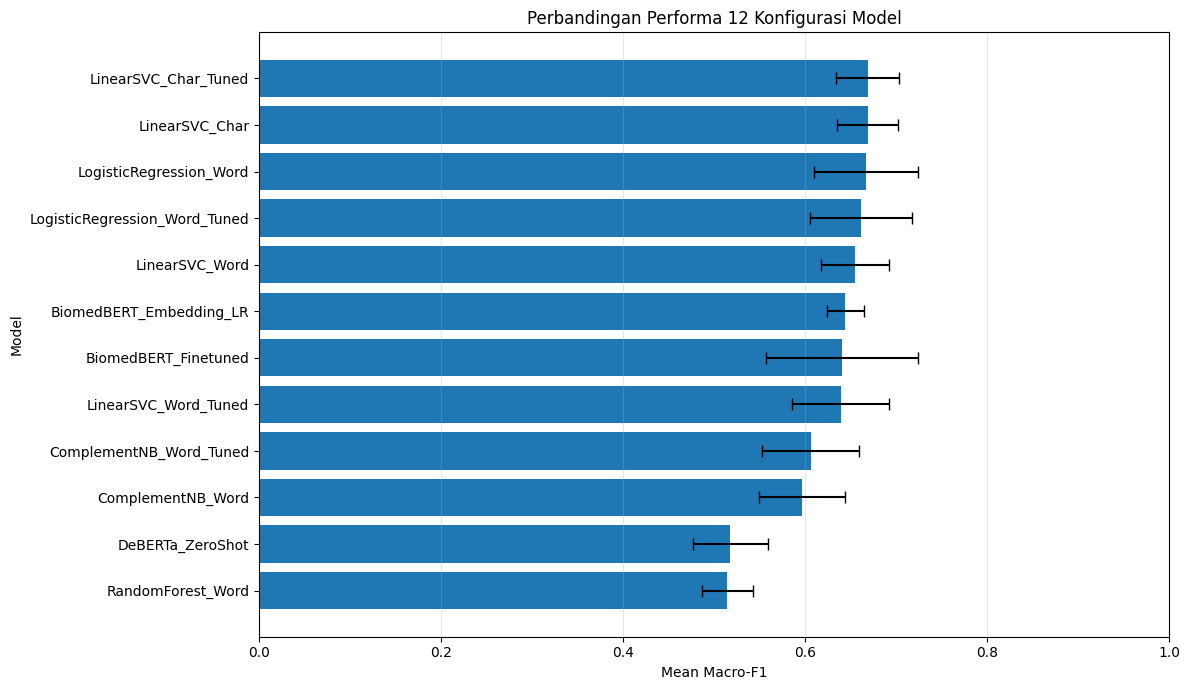

In [101]:
## Grafik Macro-F1
import matplotlib.pyplot as plt

plot_data = model_comparison.sort_values(
    "macro_f1_mean",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["model"],
    plot_data["macro_f1_mean"],
    xerr=plot_data["macro_f1_std"],
    capsize=4
)

plt.xlabel("Mean Macro-F1")
plt.ylabel("Model")
plt.title("Perbandingan Performa 12 Konfigurasi Model")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 11. Menentukan dua kandidat terbaik

In [102]:
## Final Model Selection
selected_models = [
    "LinearSVC_Char_Tuned",
    "LinearSVC_Char"
]

best_model_name = selected_models[0]

print("MODEL TERPILIH UNTUK TEMPORAL VALIDATION")
print("=" * 60)

for model_name in selected_models:
    result = model_comparison[
        model_comparison["model"] == model_name
    ].iloc[0]

    print(f"\nModel       : {model_name}")
    print(f"Macro-F1    : {result['macro_f1_mean']:.4f}")
    print(f"Std         : {result['macro_f1_std']:.4f}")
    print(f"Pooled F1   : {result['pooled_oof_macro_f1']:.4f}")
    print(f"Accuracy    : {result['accuracy']:.4f}")

# Simpan daftar model terpilih
selected_models_df = model_comparison[
    model_comparison["model"].isin(selected_models)
].copy()

selected_models_df.to_csv(
    TABLE_DIR / "selected_models_temporal_validation.csv",
    index=False
)

print("\nFile berhasil disimpan:")
print(TABLE_DIR / "selected_models_temporal_validation.csv")

MODEL TERPILIH UNTUK TEMPORAL VALIDATION

Model       : LinearSVC_Char_Tuned
Macro-F1    : 0.6690
Std         : 0.0346
Pooled F1   : 0.6707
Accuracy    : 0.8396

Model       : LinearSVC_Char
Macro-F1    : 0.6689
Std         : 0.0336
Pooled F1   : 0.6715
Accuracy    : 0.8418

File berhasil disimpan:
outputs/tables/selected_models_temporal_validation.csv


In [103]:
# MCNEMAR TEST

from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np

best_pred = predictions_dict[best_model_name].copy()

# Pastikan urutan laporan sama
best_pred = best_pred.set_index("mdr_report_key").loc[
    df["mdr_report_key"].astype(str)
]

y_true = best_pred["y_true"].astype(str).values
y_best = best_pred["y_pred"].astype(str).values

mcnemar_results = []

for model_name, pred_df in predictions_dict.items():

    if model_name == best_model_name:
        continue

    pred = pred_df.set_index("mdr_report_key").loc[
        df["mdr_report_key"].astype(str)
    ]

    y_competitor = pred["y_pred"].astype(str).values

    correct_best = (y_best == y_true)
    correct_competitor = (y_competitor == y_true)

    both_correct = np.sum(
        correct_best & correct_competitor
    )

    best_only_correct = np.sum(
        correct_best & ~correct_competitor
    )

    competitor_only_correct = np.sum(
        ~correct_best & correct_competitor
    )

    both_wrong = np.sum(
        ~correct_best & ~correct_competitor
    )

    contingency_table = [
        [both_correct, best_only_correct],
        [competitor_only_correct, both_wrong]
    ]

    result = mcnemar(
        contingency_table,
        exact=True
    )

    mcnemar_results.append({
        "best_model": best_model_name,
        "comparison_model": model_name,
        "both_correct": both_correct,
        "best_only_correct": best_only_correct,
        "competitor_only_correct": competitor_only_correct,
        "both_wrong": both_wrong,
        "p_value": result.pvalue
    })

mcnemar_df = pd.DataFrame(mcnemar_results)

# Koreksi Holm
reject, p_adjusted, _, _ = multipletests(
    mcnemar_df["p_value"],
    alpha=0.05,
    method="holm"
)

mcnemar_df["p_adjusted_holm"] = p_adjusted
mcnemar_df["significant"] = reject

mcnemar_df = mcnemar_df.sort_values(
    "p_adjusted_holm"
).reset_index(drop=True)

display(mcnemar_df)

mcnemar_df.to_csv(
    TABLE_DIR / "mcnemar_holm_results.csv",
    index=False
)

print("Hasil McNemar berhasil disimpan.")

,best_model,comparison_model,both_correct,best_only_correct,competitor_only_correct,both_wrong,p_value,p_adjusted_holm,significant
0,LinearSVC_Char_Tuned,DeBERTa_ZeroShot,2434,592,215,363,1.676931e-41,1.844624e-40,True
1,LinearSVC_Char_Tuned,BiomedBERT_Embedding_LR,2625,401,205,373,1.335834e-15,1.335834e-14,True
2,LinearSVC_Char_Tuned,RandomForest_Word,2770,256,187,391,1.209789e-03,1.088810e-02,True
3,LinearSVC_Char_Tuned,LinearSVC_Word,2924,102,144,434,8.811557e-03,7.049245e-02,False
4,LinearSVC_Char_Tuned,LinearSVC_Word_Tuned,2915,111,138,440,9.922347e-02,6.945643e-01,False
5,LinearSVC_Char_Tuned,LinearSVC_Char,3018,8,16,562,1.515896e-01,9.095378e-01,False
6,LinearSVC_Char_Tuned,LogisticRegression_Word,2913,113,135,443,1.822534e-01,9.112671e-01,False
7,LinearSVC_Char_Tuned,ComplementNB_Word,2846,180,168,410,5.554795e-01,1.000000e+00,False
8,LinearSVC_Char_Tuned,LogisticRegression_Word_Tuned,2889,137,134,444,9.033312e-01,1.000000e+00,False
9,LinearSVC_Char_Tuned,ComplementNB_Word_Tuned,2861,165,170,408,8.270463e-01,1.000000e+00,False


Hasil McNemar berhasil disimpan.


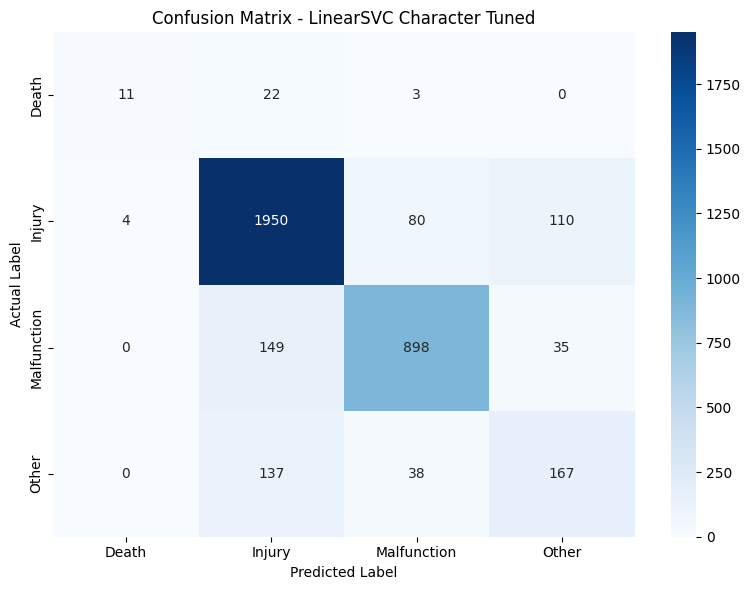

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Death       0.73      0.31      0.43        36
      Injury       0.86      0.91      0.89      2144
 Malfunction       0.88      0.83      0.85      1082
       Other       0.54      0.49      0.51       342

    accuracy                           0.84      3604
   macro avg       0.75      0.63      0.67      3604
weighted avg       0.84      0.84      0.84      3604



In [104]:
# CONFUSION MATRIX BEST MODEL


import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

best_pred = predictions_dict[best_model_name]

y_true_best = best_pred["y_true"].astype(str)
y_pred_best = best_pred["y_pred"].astype(str)

# Confusion matrix jumlah prediksi
cm = confusion_matrix(
    y_true_best,
    y_pred_best,
    labels=CLASS_ORDER
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER
)

plt.title("Confusion Matrix - LinearSVC Character Tuned")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# Classification report
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_true_best,
        y_pred_best,
        labels=CLASS_ORDER,
        zero_division=0
    )
)

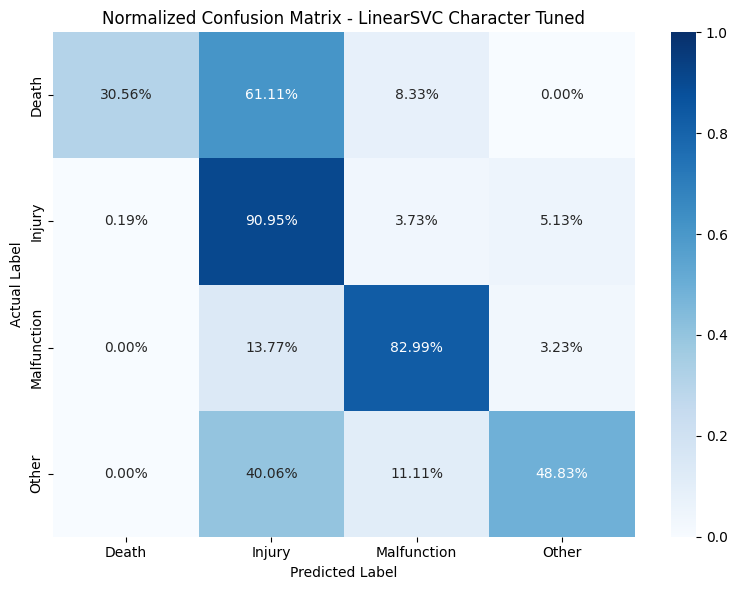

In [105]:
# NORMALIZED CONFUSION MATRIX

cm_normalized = confusion_matrix(
    y_true_best,
    y_pred_best,
    labels=CLASS_ORDER,
    normalize="true"
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER,
    vmin=0,
    vmax=1
)

plt.title("Normalized Confusion Matrix - LinearSVC Character Tuned")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# 12. Error Analysis

In [106]:
# IDENTIFIKASI KESALAHAN PREDIKSI

import pandas as pd
import numpy as np

best_model_name = "LinearSVC_Char_Tuned"

# Ambil prediksi OOF model terbaik
best_pred = predictions_dict[best_model_name].copy()

# Pastikan ID bertipe string
best_pred["mdr_report_key"] = (
    best_pred["mdr_report_key"].astype(str)
)

# Identifikasi kesalahan
best_pred["is_error"] = (
    best_pred["y_true"].astype(str)
    != best_pred["y_pred"].astype(str)
)

errors = best_pred[
    best_pred["is_error"]
].copy()

print("RINGKASAN KESALAHAN PREDIKSI")
print("=" * 55)
print(f"Total laporan       : {len(best_pred)}")
print(f"Prediksi benar      : {(~best_pred['is_error']).sum()}")
print(f"Prediksi salah      : {len(errors)}")
print(f"Persentase kesalahan: {len(errors) / len(best_pred) * 100:.2f}%")

display(
    errors[
        ["mdr_report_key", "y_true", "y_pred", "fold"]
    ].head()
)

RINGKASAN KESALAHAN PREDIKSI
Total laporan       : 3604
Prediksi benar      : 3026
Prediksi salah      : 578
Persentase kesalahan: 16.04%


,mdr_report_key,y_true,y_pred,fold
5,14296,Malfunction,Other,2
6,14624,Injury,Other,3
9,22878,Other,Malfunction,4
10,22349,Other,Injury,2
11,25312,Malfunction,Injury,3


In [107]:
# KELOMPOK PASANGAN KELAS

# Urutan kelas untuk menyeragamkan penulisan pasangan
class_rank = {
    label: i for i, label in enumerate(CLASS_ORDER)
}

def buat_pasangan(row):
    kelas = [str(row["y_true"]), str(row["y_pred"])]
    kelas = sorted(kelas, key=lambda x: class_rank[x])
    return " ↔ ".join(kelas)

errors["pasangan"] = errors.apply(
    buat_pasangan,
    axis=1
)

# Ringkasan jumlah kesalahan per pasangan
pair_summary = (
    errors["pasangan"]
    .value_counts()
    .rename_axis("pasangan")
    .reset_index(name="jumlah_kesalahan")
)

display(pair_summary)

pair_summary.to_csv(
    TABLE_DIR / "error_pair_summary.csv",
    index=False
)

,pasangan,jumlah_kesalahan
0,Injury ↔ Other,247
1,Injury ↔ Malfunction,229
2,Malfunction ↔ Other,73
3,Death ↔ Injury,26
4,Death ↔ Malfunction,3


In [108]:
# SAMPLING 50 KESALAHAN

TARGET_SAMPLE = 50

# Definisikan urutan prioritas pasangan kelas
priority_pairs = [
    "Death ↔ Injury",
    "Death ↔ Malfunction",
    "Death ↔ Other",
    "Injury ↔ Other",
    "Injury ↔ Malfunction",
    "Malfunction ↔ Other"
]

# Tambahkan kelompok berdasarkan prioritas
errors["priority"] = errors["pasangan"].apply(
    lambda x: (
        priority_pairs.index(x)
        if x in priority_pairs
        else len(priority_pairs)
    )
)

# Urutkan berdasarkan prioritas
errors_sorted = errors.sort_values(
    ["priority", "mdr_report_key"]
)

# Ambil sampel sampai mencapai 50 laporan
selected_parts = []
remaining = TARGET_SAMPLE

for priority in sorted(errors_sorted["priority"].unique()):

    group = errors_sorted[
        errors_sorted["priority"] == priority
    ]

    if remaining <= 0:
        break

    if len(group) <= remaining:
        selected = group.copy()
    else:
        selected = group.sample(
            n=remaining,
            random_state=42
        )

    selected_parts.append(selected)
    remaining -= len(selected)

error_sample = pd.concat(
    selected_parts,
    ignore_index=True
)

# Validasi jumlah sampel
print("HASIL PEMILIHAN SAMPEL")
print("=" * 50)
print(f"Jumlah kesalahan tersedia : {len(errors)}")
print(f"Jumlah sampel terpilih    : {len(error_sample)}")

if len(error_sample) != TARGET_SAMPLE:
    print(
        "PERHATIAN: Jumlah kesalahan yang tersedia "
        "tidak mencukupi untuk mengambil 50 sampel."
    )
else:
    print("Validasi jumlah sampel: BERHASIL")

assert error_sample["mdr_report_key"].is_unique

HASIL PEMILIHAN SAMPEL
Jumlah kesalahan tersedia : 578
Jumlah sampel terpilih    : 50
Validasi jumlah sampel: BERHASIL


In [109]:
#  MENYIAPKAN DATA UNTUK TELAAH MANUAL

# Kolom dari dataset asli yang diperlukan untuk telaah
review_columns = [
    "mdr_report_key",
    "event_text",
    "grup"
]

# Pastikan kolom tersedia
available_columns = [
    col for col in review_columns
    if col in df.columns
]

original_text = df[available_columns].copy()

original_text["mdr_report_key"] = (
    original_text["mdr_report_key"].astype(str)
)

# Gabungkan dengan hasil prediksi
error_review = error_sample.merge(
    original_text,
    on="mdr_report_key",
    how="left",
    validate="one_to_one"
)

# Kolom kategori dan catatan diisi setelah telaah manusia
error_review["kategori"] = ""
error_review["catatan"] = ""

# Susun kolom agar mudah dibaca
final_columns = [
    "mdr_report_key",
    "y_true",
    "y_pred",
    "pasangan",
    "fold",
    "grup",
    "event_text",
    "kategori",
    "catatan"
]

error_review = error_review[
    [col for col in final_columns if col in error_review.columns]
]

# Validasi narasi
print("VALIDASI DATA TELAAH")
print("=" * 50)
print(f"Jumlah baris             : {len(error_review)}")
print(
    "Narasi kosong            : "
    f"{error_review['event_text'].isna().sum()}"
)
print(
    "ID duplikat              : "
    f"{error_review['mdr_report_key'].duplicated().sum()}"
)

display(error_review.head(10))

VALIDASI DATA TELAAH
Jumlah baris             : 50
Narasi kosong            : 0
ID duplikat              : 0


,mdr_report_key,y_true,y_pred,pasangan,fold,grup,event_text,kategori,catatan
0,12546715,Death,Injury,Death ↔ Injury,1,2345,"MY(B)(6) YEAR OLD SON'S TEETH, HANDS, LIPS, LEGS WERE BURNED DURING AN MRI. NECK MUSCLES WERE DAMAGED. MY HUSBAND AN...",,
1,12688097,Death,Injury,Death ↔ Injury,0,2351,IT WAS REPORTED TO SIEMENS THAT AN ADVERSE EVENT OCCURRED WHILE OPERATING THE MAGNETOM AVANTO DOT SYSTEM. IT WAS STA...,,
2,12739907,Death,Injury,Death ↔ Injury,2,2355,"IT WAS REPORTED THAT A PATIENT WAS BEING SCANNED, AND DUE TO HIS CRITICAL CONDITION, NEEDED TO STAY ON OXYGEN DURING...",,
3,139003,Injury,Death,Death ↔ Injury,0,61,"IT WAS REPORTED TO GE THAT DURING THE INSTALLATION OF A COLDHEAD TO THE SIGNA MR SYS, THE FIELD ENGINEER WAS INJURED...",,
4,16370299,Death,Injury,Death ↔ Injury,1,2506,PHILIPS RECEIVED A REPORT THAT A PATIENT WHO HAD AN IMPLANTED PACE MAKER DIED 2 HOURS AFTER UNDERGOING AN MR EXAMINA...,,
5,1648230,Death,Injury,Death ↔ Injury,0,905,"A FATALITY INVOLVING A THIRD PARTY FIELD ENGINEER (FE) WAS REPORTED TO GE HEALTHCARE ON MARCH 4, 2010 BY THE DISTRIB...",,
6,16786184,Injury,Death,Death ↔ Injury,3,2529,"IT WAS REPORTED THAT A PATIENT WAS SCANNED WITH AN IMPLANTED DEFIBRILLATOR. DURING THE SCAN, THE PATIENT WENT INTO C...",,
7,17802244,Death,Injury,Death ↔ Injury,0,2591,"IT WAS REPORTED BY (B)(6) THAT FOLLOWING AN MRI SCAN, A PATIENT WITH A CARDIO STIMULATOR EXPIRED. NO ADDITIONAL INFO...",,
8,22108787,Death,Injury,Death ↔ Injury,4,3095,REF COMP #(B)(4). UPDATE: FUJIFILM HEALTHCARE AMERICAS CORPORATION CONFIRMED THAT THE PATIENT PASSED AWAY AFTER BEIN...,,
9,22644009,Death,Injury,Death ↔ Injury,2,3141,SIEMENS HEALTHINEERS BECAME AWARE OF A FATAL INCIDENT INVOLVING THE MAGNETOM ESPREE SYSTEM. THE INCIDENT REPORTEDLY ...,,


In [110]:
# EXPORT ERROR ANALYSIS

error_review_path = (
    TABLE_DIR / "error_telaah_50.csv"
)

error_review.to_csv(
    error_review_path,
    index=False
)

print("File telaah berhasil disimpan:")
print(error_review_path)

File telaah berhasil disimpan:
outputs/tables/error_telaah_50.csv


TEST


In [111]:
from pathlib import Path

OUTPUT_DIR = Path("outputs")

print("DAFTAR SELURUH OUTPUT")
print("=" * 60)

for folder in ["predictions", "tables"]:
    folder_path = OUTPUT_DIR / folder

    print(f"\nFolder: {folder}")

    if folder_path.exists():
        files = sorted(folder_path.glob("*"))

        for file in files:
            if file.is_file():
                size_kb = file.stat().st_size / 1024
                print(f"- {file.name} ({size_kb:.2f} KB)")
    else:
        print("Folder tidak ditemukan.")

DAFTAR SELURUH OUTPUT

Folder: predictions
- biomedbert_embedding_lr.csv (378.91 KB)
- biomedbert_finetuned.csv (383.15 KB)
- complement_nb_test.csv (94.28 KB)
- complementnb_word.csv (94.28 KB)
- complementnb_word_tuned.csv (94.42 KB)
- deberta_zeroshot.csv (382.64 KB)
- linearsvc_char.csv (94.80 KB)
- linearsvc_char_tuned.csv (94.80 KB)
- linearsvc_word.csv (94.62 KB)
- linearsvc_word_tuned.csv (94.72 KB)
- logisticregression_word.csv (94.67 KB)
- logisticregression_word_tuned.csv (94.51 KB)
- randomforest_word.csv (93.87 KB)

Folder: tables
- all_models_comparison.csv (1.24 KB)
- all_models_fold_results.csv (2.69 KB)
- biomedbert_embedding_lr_summary.csv (0.21 KB)
- biomedbert_finetuned_fold_metrics.csv (0.37 KB)
- biomedbert_finetuned_training_history.csv (0.66 KB)
- deberta_zeroshot_fold_metrics.csv (0.14 KB)
- deberta_zeroshot_summary.csv (0.16 KB)
- error_pair_summary.csv (0.14 KB)
- error_telaah_50.csv (39.61 KB)
- mcnemar_holm_results.csv (1.19 KB)
- selected_models_temporal_v

In [112]:
import shutil
from pathlib import Path

OUTPUT_DIR = Path("outputs")
ZIP_PATH = Path("outputs_UAS_DataMining.zip")

# Pastikan folder output tersedia
assert OUTPUT_DIR.exists(), "Folder outputs tidak ditemukan!"

# Buat ZIP dari seluruh isi folder outputs
shutil.make_archive(
    str(ZIP_PATH.with_suffix("")),
    "zip",
    root_dir=".",
    base_dir="outputs"
)

print("ZIP berhasil dibuat!")
print(f"Nama file : {ZIP_PATH.name}")
print(f"Ukuran    : {ZIP_PATH.stat().st_size / (1024 * 1024):.2f} MB")

ZIP berhasil dibuat!
Nama file : outputs_UAS_DataMining.zip
Ukuran    : 10.47 MB


In [113]:
from google.colab import files

files.download("outputs_UAS_DataMining.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>